# Customs Taxpayer Risk Profiling Model: release 1

The working record of the model, stage by stage. It reads the extracts in `data/`, runs the same model code
as production (`src/ctrp/core.py`), and shows the evidence behind each decision. The decisions themselves are
logged in `docs/DECISIONS.md`.

| Stage | Content | Section | Status |
|---|---|---|---|
| 1 | The source data and how it was cleaned | 1 | Closed |
| 2 | One extract per snapshot date | 2 | Closed |
| 3 | Feature exploration: distributions, small counts, thresholds | 3 | Closed |
| 4 | Scorecard | 3.8 | Adopted |
| 5 | Peer groups | 4 | Adopted (main goods x size) |
| 6 | Pattern check | 5 | Decided: a note, no points |
| 7 | Scores, bands and back-test | 6 to 8 | Bands provisional |
| 8 | Challenger models, round 1 | 9 | Done: scorecard kept |

**How to read it.** Each section starts with a short note in plain words, then the chart. Every code cell
opens with a `What:` and `Why:` line. Run All takes about fifteen minutes (section 9 alone takes about ten).

In [1]:
# What: libraries, chart style and the extracts.
# Why:  one place for the look of every chart, so they read as one set.
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from matplotlib.colors import LinearSegmentedColormap

try:
    import ctrp
except ImportError:                       # not installed: use the src folder beside this notebook
    sys.path.insert(0, str(Path.cwd().parent / 'src'))
from ctrp import core as M, report as R
from ctrp.models import challengers as CH
from ctrp.utils import CHARTS_DIR, DATA_DIR, RESULTS_DIR, hit_rate, lift as lift_at

SURFACE, INK, INK2, GRID, MUTED = '#fcfcfb', '#0b0b0b', '#52514e', '#e6e5e0', '#bdbcb7'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'          # categorical colours, fixed order
RAMP = ['#cde2fb', '#9ec5f4', '#5598e7', '#1c5cab', '#0d366b']  # one hue, light to dark (bands)
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'text.color': INK, 'xtick.color': INK2,
    'ytick.color': INK2, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10, 'lines.linewidth': 2,
    'figure.dpi': 110, 'legend.frameon': False})
pct = mt.PercentFormatter(1.0, decimals=0)

def _big(x, _=None):
    if abs(x) >= 1e12: return f'{x/1e12:.1f}'.rstrip('0').rstrip('.') + 'T'
    if abs(x) >= 1e9: return f'{x/1e9:.1f}'.rstrip('0').rstrip('.') + 'B'
    if abs(x) >= 1e6: return f'{x/1e6:.1f}'.rstrip('0').rstrip('.') + 'M'
    if abs(x) >= 1e3: return f'{x/1e3:.1f}'.rstrip('0').rstrip('.') + 'k'
    return f'{x:.0f}'
big = mt.FuncFormatter(_big)

def snap_label(s):
    return pd.to_datetime(s).strftime('%b %y')

def bar_labels(ax, bars, fmt='{:,.0f}', inside=False, color=INK2):
    # What: print each bar's value at its end.  Why: the reader should not have to read the axis.
    for b in bars:
        w = b.get_width()
        ax.text(w, b.get_y() + b.get_height() / 2, '  ' + fmt.format(w), va='center', fontsize=8, color=color)

# Every chart is also saved as a PNG in results/charts, ready for slides
CHART_DIR = CHARTS_DIR
CHART_DIR.mkdir(parents=True, exist_ok=True)
_show, _chart_no = plt.show, [0]
def _save_and_show(*args, **kwargs):
    _chart_no[0] += 1
    plt.gcf().savefig(CHART_DIR / f'chart_{_chart_no[0]:02d}.png', dpi=150, bbox_inches='tight')
    _show(*args, **kwargs)
plt.show = _save_and_show

DATA = DATA_DIR
ex = {f.stem.replace('bt_', ''): M.load_extract(f) for f in sorted(DATA.glob('bt_*.csv'))}
live_file = DATA / 'live_2026-09-30.csv'
latest = list(ex)[-1]
D = {snap: M.derive(raw) for snap, raw in ex.items()}       # derived columns, every snapshot
d = D[latest]
d['group'] = np.where(d['adequate'], '10+ declarations', 'Fewer than 10')
ad = d[d['adequate']]
ORDER = ['Fewer than 10', '10+ declarations']
print(f'{len(ex)} back-test extracts loaded; latest {latest}: {len(d):,} taxpayers, {len(ad):,} with 10+ declarations')

6 back-test extracts loaded; latest 2026-03-31: 58,161 taxpayers, 7,725 with 10+ declarations


## 1. The source data

Source: `dm_modeled_ura_datascience.vw_cstm_AEO_model`, one row per declaration item, all regimes, from
November 2012. The numbers in this section come from the Stage 1 queries in `00_eda_cleaning.sql` (query
codes in brackets) and cover the 24 months to September 2026 unless stated.

### 1.1 Is the data complete?

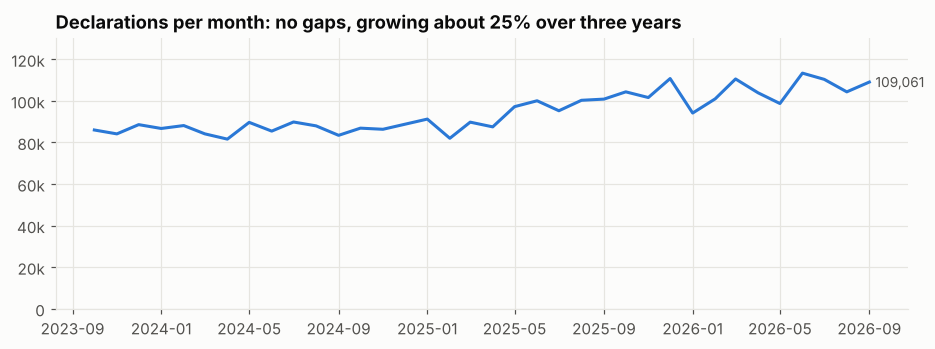

In [2]:
# What: declarations per month (query A2).  Why: gaps or sudden drops would break any 24-month window.
months = pd.Series({
 '2023-10':86007,'2023-11':84135,'2023-12':88582,'2024-01':86738,'2024-02':88140,'2024-03':84148,
 '2024-04':81614,'2024-05':89674,'2024-06':85466,'2024-07':89854,'2024-08':87990,'2024-09':83440,
 '2024-10':86889,'2024-11':86349,'2024-12':88759,'2025-01':91248,'2025-02':82018,'2025-03':89779,
 '2025-04':87508,'2025-05':97225,'2025-06':100057,'2025-07':95263,'2025-08':100287,'2025-09':100856,
 '2025-10':104350,'2025-11':101616,'2025-12':110744,'2026-01':94155,'2026-02':100988,'2026-03':110546,
 '2026-04':103884,'2026-05':98741,'2026-06':113352,'2026-07':110357,'2026-08':104350,'2026-09':109061})
fig, ax = plt.subplots(figsize=(10, 3.2))
x = pd.to_datetime(months.index)
ax.plot(x, months.values, color=BLUE)
ax.set_ylim(0, months.max() * 1.15); ax.yaxis.set_major_formatter(big)
ax.set_title('Declarations per month: no gaps, growing about 25% over three years')
ax.annotate(f'{months.iloc[-1]:,}', (x[-1], months.iloc[-1]), xytext=(4, 0), textcoords='offset points',
            va='center', color=INK2, fontsize=9)
plt.show()

### 1.2 What is in the view, and what the model keeps

The view holds every customs regime. The model keeps **IM4** (home use) and **IM7** (warehousing): these are
the regimes where duty is assessed and paid, so a top-up means revenue that was at risk. Transit, export and
re-export regimes carry guarantees or suspended amounts, not duty paid.

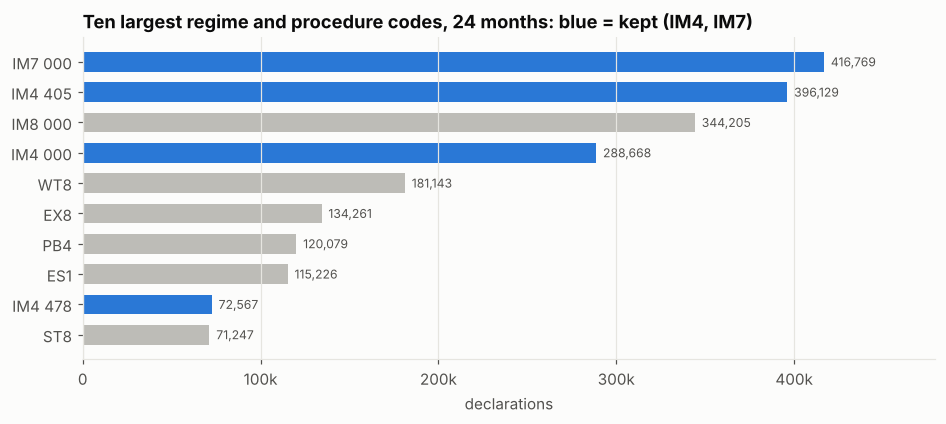

IM4 and IM7 in the top ten: 1,174,133 declarations; IM4 000 alone has 49,889 taxpayers, IM4 405 has 2,927.


In [3]:
# What: declarations by regime and procedure (query D2).  Why: shows the size of what is kept and dropped.
reg = pd.Series({'IM7 000': 416769, 'IM4 405': 396129, 'IM8 000': 344205, 'IM4 000': 288668, 'WT8': 181143,
                 'EX8': 134261, 'PB4': 120079, 'ES1': 115226, 'IM4 478': 72567, 'ST8': 71247}).sort_values()
kept = [k.startswith(('IM4', 'IM7')) for k in reg.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.barh(reg.index, reg.values, color=[BLUE if k else MUTED for k in kept], height=0.65)
bar_labels(ax, bars)
ax.xaxis.set_major_formatter(big); ax.grid(axis='y', visible=False); ax.set_xlim(0, reg.max() * 1.15)
ax.set_title('Ten largest regime and procedure codes, 24 months: blue = kept (IM4, IM7)')
ax.set_xlabel('declarations')
plt.show()
print(f"IM4 and IM7 in the top ten: {reg[kept].sum():,} declarations; IM4 000 alone has 49,889 taxpayers, "
      f"IM4 405 has 2,927.")

### 1.3 Problems found in the data, and the rule each one led to

Three problems would have distorted every count if left in:

* **Repeated items.** 14,215 items appear more than once, adding 1,478,314 extra rows (B1). The copies are
  identical, so each item is kept once.
* **Missing TINs.** 479,719 declarations have no taxpayer TIN (C1), but all of them sit in regimes the model
  does not use (H3). No IM4 or IM7 declaration lacks a TIN.
* **The top-up column means two things.** On flagged declarations `top_up_amt` is the top-up. On unflagged
  ones it holds the **final tax** (99.85% of the time, H2). Reading it as a top-up would invent billions of
  shillings of top-ups. Rule: a top-up is a declaration flagged Y whose final tax is above the original.

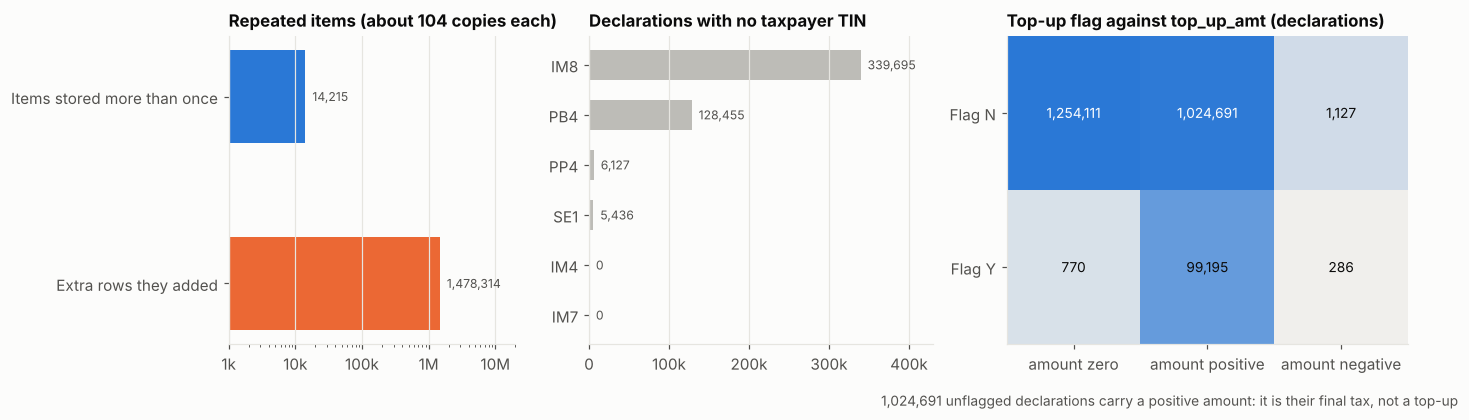

In [4]:
# What: the three data problems in numbers (B1, H3, B3).  Why: each one is the reason for a cleaning rule.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={'width_ratios': [1, 1.2, 1.4]})

ax = axes[0]                                                          # duplicates
dup = pd.Series({'Extra rows they added': 1478314, 'Items stored more than once': 14215})
bars = ax.barh(dup.index, dup.values, color=[ORANGE, BLUE], height=0.5)
bar_labels(ax, bars)
ax.set_xscale('log'); ax.set_xlim(1e3, 2e7); ax.xaxis.set_major_formatter(big); ax.grid(axis='y', visible=False)
ax.set_title('Repeated items (about 104 copies each)', fontsize=11)

ax = axes[1]                                                          # missing TINs by regime
tin = pd.Series({'IM8': 339695, 'PB4': 128455, 'PP4': 6127, 'SE1': 5436, 'IM4': 0, 'IM7': 0}).iloc[::-1]
bars = ax.barh(tin.index, tin.values, color=[BLUE if r in ('IM4', 'IM7') else MUTED for r in tin.index], height=0.6)
bar_labels(ax, bars)
ax.xaxis.set_major_formatter(big); ax.set_xlim(0, 4.3e5); ax.grid(axis='y', visible=False)
ax.set_title('Declarations with no taxpayer TIN', fontsize=11)

ax = axes[2]                                                          # flag vs amount
b3 = pd.DataFrame({'zero': [1254111, 770], 'positive': [1024691, 99195], 'negative': [1127, 286]},
                  index=['Flag N', 'Flag Y'])
im = ax.imshow(np.log10(b3.values + 1), cmap=LinearSegmentedColormap.from_list('b', ['#f0efec', BLUE]), aspect='auto')
ax.set_xticks(range(3), ['amount zero', 'amount positive', 'amount negative']); ax.set_yticks(range(2), b3.index)
ax.grid(False)
for i in range(2):
    for j in range(3):
        v = b3.values[i, j]
        ax.text(j, i, f'{v:,}', ha='center', va='center', fontsize=9, color='white' if v > 5e5 else INK)
ax.set_title('Top-up flag against top_up_amt (declarations)', fontsize=11)
fig.text(0.62, -0.04, '1,024,691 unflagged declarations carry a positive amount: it is their final tax, not a top-up',
         fontsize=9, color=INK2)
plt.tight_layout(); plt.show()

### 1.4 How often the things we score actually happen

Share of declarations in the view over 24 months (E1, E2, G1; preferential treatment is a share of items). Top-ups are rare (about 1 in 24 declarations),
which is why a taxpayer's top-up record says a lot, and why one or two declarations cannot establish it.

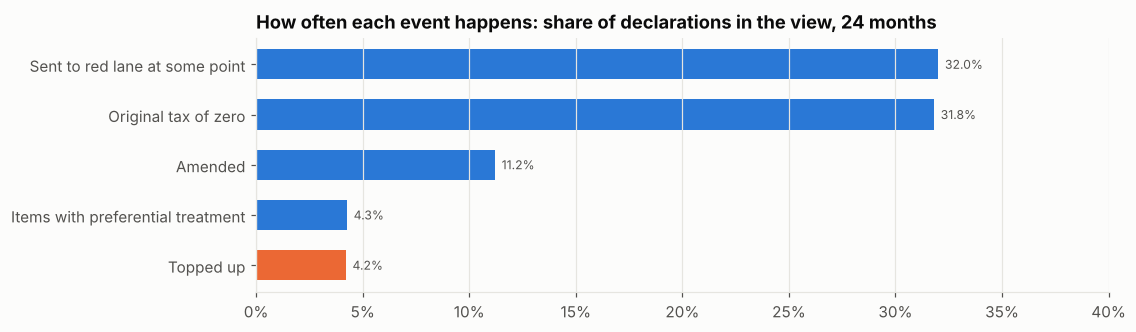

In [5]:
# What: base rates of the events behind the parameters.  Why: sets expectations for every threshold.
ev = pd.Series({'Sent to red lane at some point': 0.32, 'Original tax of zero': 0.318,
                'Amended': 0.112, 'Items with preferential treatment': 336931 / (336931 + 7578855),
                'Topped up': 0.042}).sort_values()
fig, ax = plt.subplots(figsize=(10, 3.0))
bars = ax.barh(ev.index, ev.values, color=[ORANGE if k == 'Topped up' else BLUE for k in ev.index], height=0.6)
bar_labels(ax, bars, fmt='{:.1%}')
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 0.4); ax.grid(axis='y', visible=False)
ax.set_title('How often each event happens: share of declarations in the view, 24 months')
plt.show()

### 1.5 Prices and values span a huge range

A kilogram of declared goods runs from UGX 69 to UGX 17 million (F3). That range is real: cement and
phones are both in the data. So a price can only be judged against **the same HS code**, never against
the average of everything. This is why PAR_076 uses an HS benchmark and why anything below 1% of its HS
median is treated as a keying error, not undervaluation.

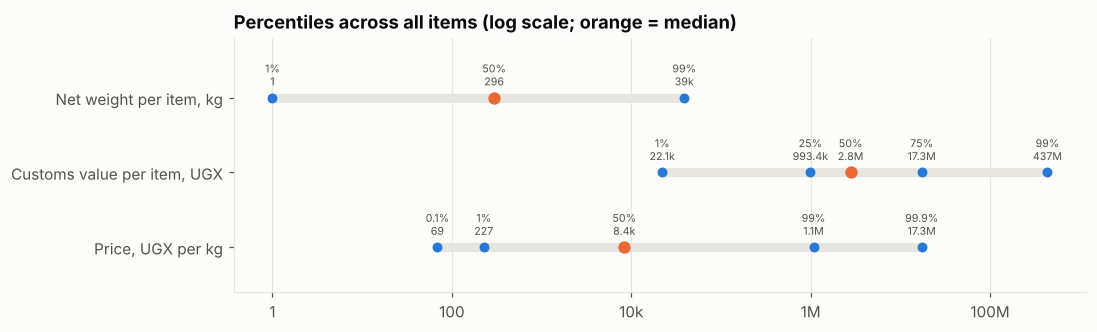

In [6]:
# What: percentiles of price per kg, value per item and weight per item (F3).  Why: shows why prices are judged within HS code.
f3 = {'Price, UGX per kg': {'0.1%': 69, '1%': 227, '50%': 8362, '99%': 1077012, '99.9%': 17318352},
      'Customs value per item, UGX': {'1%': 22141, '25%': 993445, '50%': 2.79e6, '75%': 17.3e6, '99%': 437e6},
      'Net weight per item, kg': {'1%': 1, '50%': 296, '99%': 39000}}
fig, ax = plt.subplots(figsize=(10, 3.0))
for i, (name, q) in enumerate(f3.items()):
    vals = list(q.values())
    ax.plot([min(vals), max(vals)], [i, i], color=GRID, linewidth=6, solid_capstyle='round', zorder=1)
    for k, v in q.items():
        ax.scatter(v, i, s=50 if k == '50%' else 30, color=ORANGE if k == '50%' else BLUE, zorder=3)
        ax.annotate(f'{k}\n{_big(v)}', (v, i), xytext=(0, 8), textcoords='offset points', ha='center',
                    fontsize=7, color=INK2)
ax.set_xscale('log'); ax.set_yticks(range(len(f3)), list(f3)); ax.set_ylim(-0.6, len(f3) - 0.2)
ax.xaxis.set_major_formatter(big); ax.grid(axis='y', visible=False)
ax.set_title('Percentiles across all items (log scale; orange = median)')
plt.show()

### 1.6 Most taxpayers declare very little

Taxpayers by number of declarations in 24 months, all regimes (G2). This shape drives two later decisions:
the small-count protection (3.3) and keeping peer groups and pattern points for taxpayers with 10 or more
declarations.

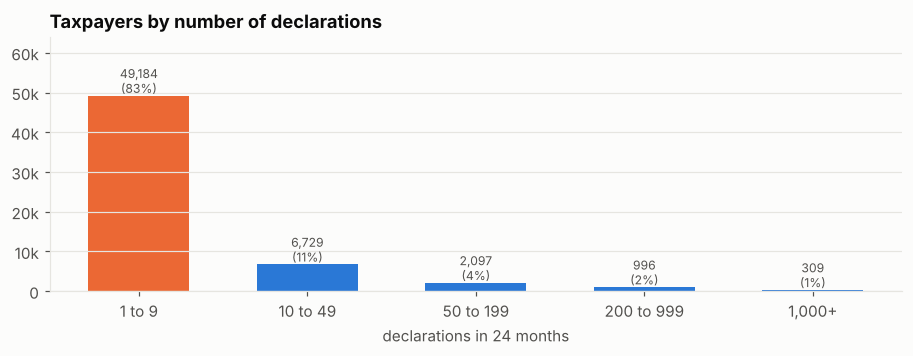

In [7]:
# What: taxpayers by activity level (G2).  Why: most taxpayers have too little history for a rate to mean much.
g2 = pd.Series({'1 to 9': 49184, '10 to 49': 6729, '50 to 199': 2097, '200 to 999': 996, '1,000+': 309})
fig, ax = plt.subplots(figsize=(10, 3.0))
bars = ax.bar(g2.index, g2.values, color=[ORANGE] + [BLUE] * 4, width=0.6)
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f'{b.get_height():,.0f}\n({b.get_height() / g2.sum():.0%})',
            ha='center', va='bottom', fontsize=8, color=INK2)
ax.set_ylim(0, g2.max() * 1.3); ax.yaxis.set_major_formatter(big); ax.grid(axis='x', visible=False)
ax.set_xlabel('declarations in 24 months'); ax.set_title('Taxpayers by number of declarations')
plt.show()

### 1.7 Cleaning rules applied in every extract

| Rule | Why |
|---|---|
| IM4 and IM7 only | Duty-paid regimes (1.2) |
| Valid 10-digit TIN; cancelled declarations out | All valid TINs are 10 digits; about 14,000 cancelled declarations carry no real liability |
| One row per item | 1.48 million repeated rows (1.3) |
| Tax amounts once per declaration | Tax is repeated on every item row |
| Top-up = flag Y and final tax above original; amount = final minus original | `top_up_amt` holds final tax on unflagged declarations (1.3) |
| Blank original tax filled with the final tax | Blank means unchanged |
| APC 483 excluded | Destroyed or abandoned goods, dummy reconciliation entries |
| Prices judged within HS code; below 1% of the HS median = keying error | Prices span five orders of magnitude (1.5) |

## 2. The extracts

One extract per snapshot date: features from the 24 months before, outcomes from the 6 months after. The
model never sees the future: it is scored on the history and judged on what came next. All six back-test
extracts passed `python main.py check`.

In [8]:
# What: size and base rates of each extract.  Why: the yardstick each snapshot is judged against.
rows = []
for snap, x in ex.items():
    decl = x['entries_24m'].sum()
    rows.append(dict(snapshot=snap, taxpayers=len(x), declarations=decl,
                     topped_up_share=(x['top_up_entry_rate'] * x['entries_24m']).sum() / decl,
                     outcome_hit_rate=hit_rate(x)))
ext = pd.DataFrame(rows).set_index('snapshot')
ext.style.format({'taxpayers': '{:,}', 'declarations': '{:,}', 'topped_up_share': '{:.1%}',
                  'outcome_hit_rate': '{:.1%}'})

,taxpayers,declarations,topped_up_share,outcome_hit_rate
snapshot,,,,
2023-09-30,"49,699","967,757",8.5%,12.8%
2024-03-31,"51,138","996,507",9.1%,11.3%
2024-09-30,"53,927","1,032,038",9.4%,7.5%
2025-03-31,"55,110","1,076,894",8.6%,7.2%
2025-09-30,"56,691","1,120,008",7.7%,7.2%
2026-03-31,"58,161","1,198,776",6.5%,7.0%


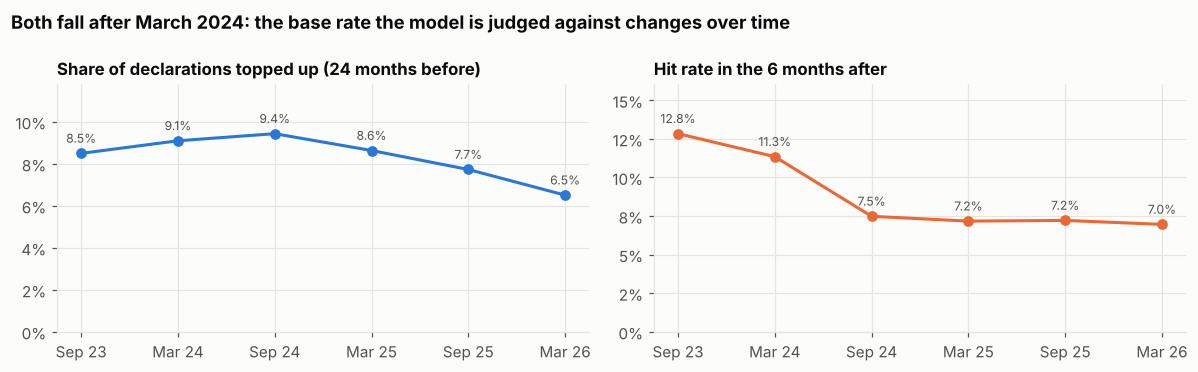

In [9]:
# What: top-up share and later hit rate by snapshot.  Why: the base rate changes, so each snapshot is judged on its own.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
s = [snap_label(i) for i in ext.index]
for ax, col, title, colr in [(axes[0], 'topped_up_share', 'Share of declarations topped up (24 months before)', BLUE),
                             (axes[1], 'outcome_hit_rate', 'Hit rate in the 6 months after', ORANGE)]:
    ax.plot(s, ext[col], color=colr, marker='o', markersize=6)
    ax.set_ylim(0, ext[col].max() * 1.25); ax.yaxis.set_major_formatter(pct); ax.set_title(title, fontsize=11)
    for xi, yi in zip(s, ext[col]):
        ax.annotate(f'{yi:.1%}', (xi, yi), xytext=(0, 7), textcoords='offset points', ha='center', fontsize=8, color=INK2)
fig.suptitle('Both fall after March 2024: the base rate the model is judged against changes over time',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

**Hit rate** = share of red or yellow declarations that ended in a top-up. The step down after March 2024 is
a question for the Risk team. It does not distort the back-test, because each snapshot is judged against its
own hit rate.

## 3. Feature exploration

### 3.1 Who is in the population

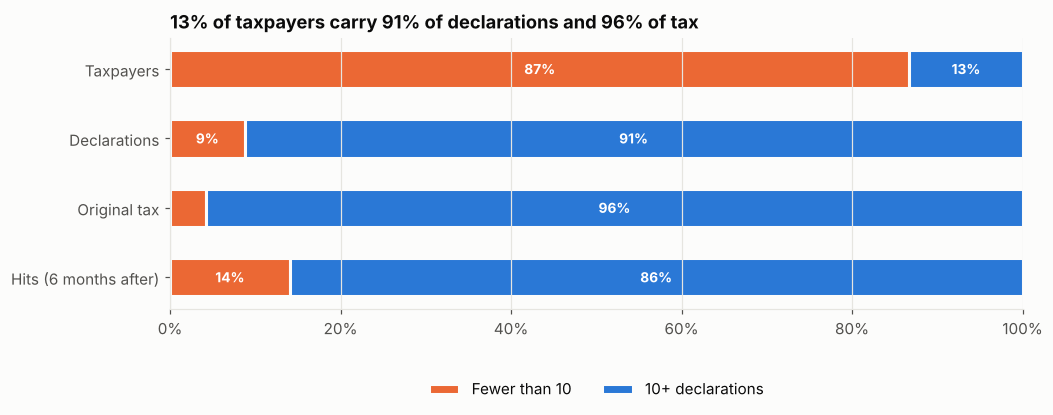

In [10]:
# What: share of taxpayers, declarations, tax and later hits by history group.  Why: tells us where the risk sits.
share = pd.DataFrame({
    'Taxpayers': d.groupby('group').size(),
    'Declarations': d.groupby('group')['entries_24m'].sum(),
    'Original tax': d.groupby('group')['total_original_tax'].sum(),
    'Hits (6 months after)': d.groupby('group')['out_checked_hits'].sum()})
share = share / share.sum()
fig, ax = plt.subplots(figsize=(10, 3.2))
left = np.zeros(len(share.columns))
for g, colr in zip(ORDER, [ORANGE, BLUE]):
    vals = share.loc[g].values
    ax.barh(share.columns[::-1], vals[::-1], left=left[::-1], color=colr, label=g, height=0.55, edgecolor=SURFACE, linewidth=2)
    for i, (v, l) in enumerate(zip(vals[::-1], left[::-1])):
        if v > 0.06:
            ax.text(l + v / 2, i, f'{v:.0%}', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    left += vals
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 1); ax.grid(axis='y', visible=False)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.38), ncol=2)
ax.set_title(f'{share.loc["10+ declarations","Taxpayers"]:.0%} of taxpayers carry '
             f'{share.loc["10+ declarations","Declarations"]:.0%} of declarations and '
             f'{share.loc["10+ declarations","Original tax"]:.0%} of tax')
plt.show()

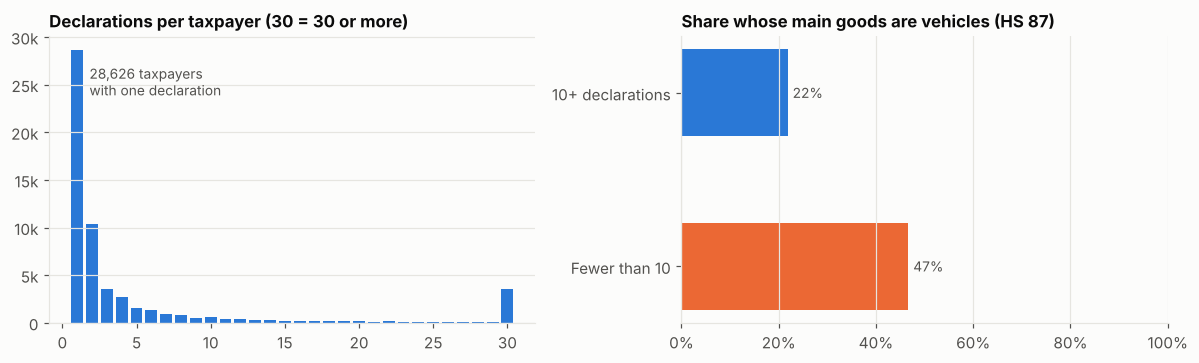

In [11]:
# What: declarations per taxpayer, and how many small taxpayers mainly import vehicles.
# Why:  the typical small taxpayer is a one-off vehicle importer, not a trader.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
counts = d['entries_24m'].clip(upper=30).value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color=BLUE, width=0.8)
axes[0].set_title('Declarations per taxpayer (30 = 30 or more)', fontsize=11)
axes[0].yaxis.set_major_formatter(big); axes[0].grid(axis='x', visible=False)
axes[0].annotate(f'{counts.loc[1]:,} taxpayers\nwith one declaration', (1, counts.loc[1]),
                 xytext=(8, -10), textcoords='offset points', fontsize=9, color=INK2, va='top')
vs = pd.crosstab(d['group'], d['dominant_hs_chapter'] == 87, normalize='index').reindex(ORDER)[True]
axes[1].barh(ORDER, vs.values, color=[ORANGE, BLUE], height=0.5)
for i, v in enumerate(vs.values):
    axes[1].text(v + 0.01, i, f'{v:.0%}', va='center', fontsize=9, color=INK2)
axes[1].set_xlim(0, 1); axes[1].xaxis.set_major_formatter(pct); axes[1].grid(axis='y', visible=False)
axes[1].set_title('Share whose main goods are vehicles (HS 87)', fontsize=11)
plt.tight_layout(); plt.show()

### 3.2 How taxpayers trade: the raw features

Distributions of the trading measures used for peer groups and the pattern check, for both history groups.
Each panel is scaled so the two groups can be compared (share of the group, not counts). Values and counts
are on a log scale because a few taxpayers are hundreds of times larger than the rest.

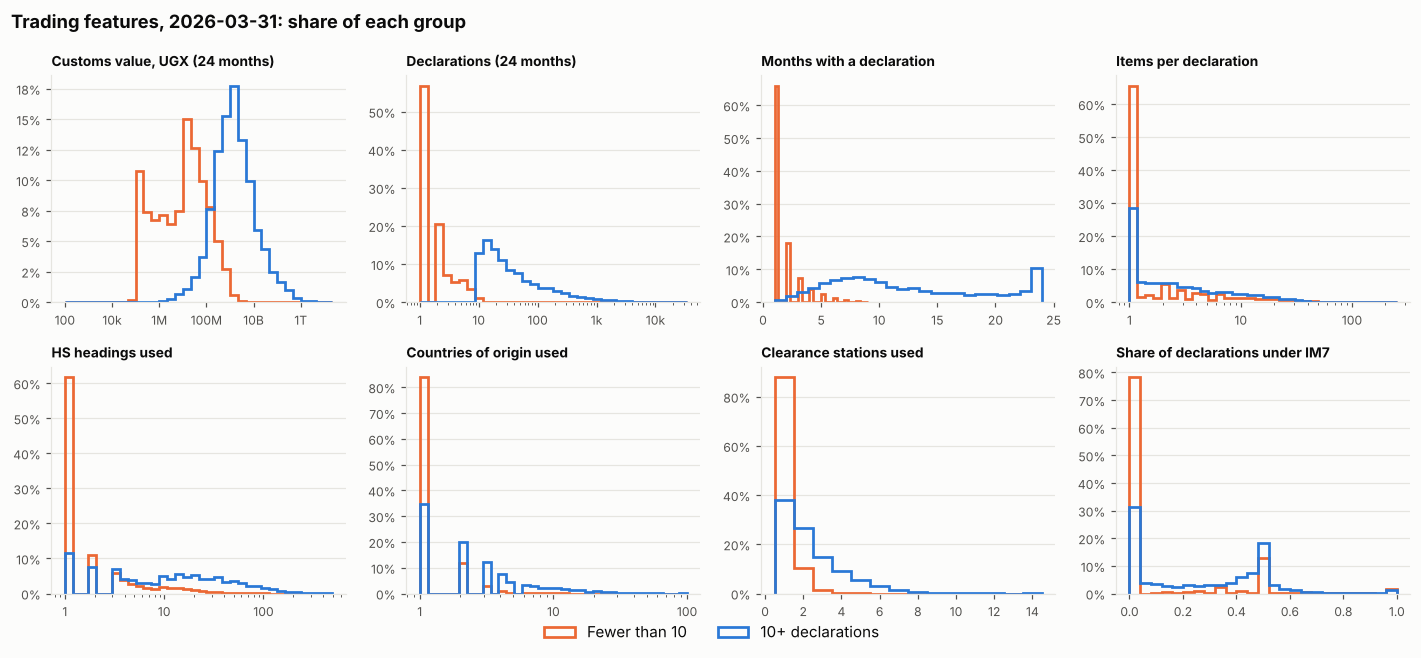

In [12]:
# What: distributions of the trading-structure features, small vs regular taxpayers.
# Why:  shows how skewed and lumpy they are (this matters for peer groups in section 4).
feats = [('total_customs_value', 'Customs value, UGX (24 months)', True),
         ('entries_24m', 'Declarations (24 months)', True),
         ('active_months', 'Months with a declaration', False),
         ('avg_items_per_entry', 'Items per declaration', True),
         ('hs_headings_used', 'HS headings used', True),
         ('origins_used', 'Countries of origin used', True),
         ('stations_used_24m', 'Clearance stations used', False),
         ('im7_share', 'Share of declarations under IM7', False)]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.8))
for ax, (col, title, logx) in zip(axes.flat, feats):
    x_all = d[col].dropna()
    if logx:
        x_all = x_all[x_all > 0]
        bins = np.logspace(np.log10(x_all.min()), np.log10(x_all.max()), 35)
        ax.set_xscale('log')
    else:
        bins = 24 if col == 'active_months' else (np.arange(0.5, 15.5, 1) if col == 'stations_used_24m' else 25)
    for g, colr in zip(ORDER, [ORANGE, BLUE]):
        v = d.loc[d['group'] == g, col].dropna()
        v = v[v > 0] if logx else v
        ax.hist(v, bins=bins, weights=np.ones(len(v)) / len(v), histtype='step', color=colr, linewidth=1.8, label=g)
    ax.set_title(title, fontsize=9); ax.yaxis.set_major_formatter(pct); ax.tick_params(labelsize=8)
    if logx:
        ax.xaxis.set_major_formatter(big)
    ax.grid(axis='x', visible=False)
handles, labs = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labs, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.03))
fig.suptitle(f'Trading features, {latest}: share of each group', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

### 3.3 The small-count problem, and the protection for small traders

A rate built on one or two declarations can only be 0%, 50% or 100%. The first chart shows the amendment rate
against the number of declarations: the spread at the left is chance, not behaviour.

The protection (credibility weighting, K = 10) pulls each rate towards the population average with weight
n / (n + 10). A taxpayer with 2 declarations keeps 17% of their own rate; one with 100 keeps 91%. It only ever
lowers a rate, so a clean small trader is never given points for other people's behaviour.

In the second chart below: almost no small taxpayer reaches the maximum after weighting. Regular taxpayers
with 10 to 30 declarations also come down (at 10 declarations they keep half their own rate), while large
traders barely move.

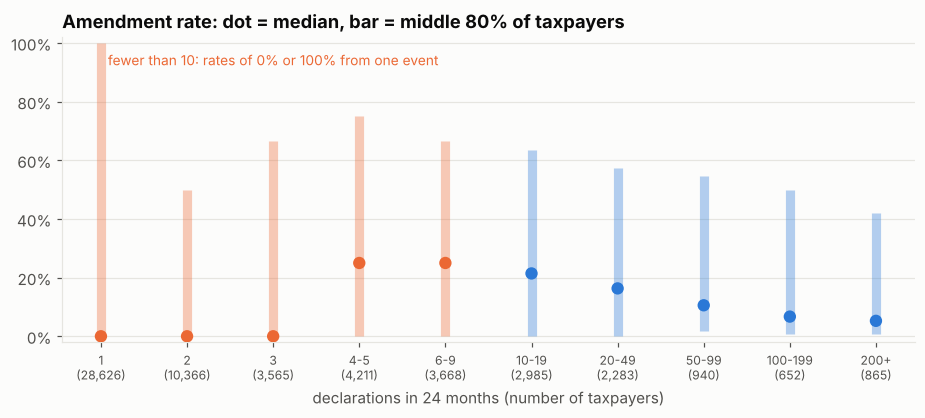

In [13]:
# What: amendment rate by number of declarations.  Why: shows that rates on few declarations are noise.
bins = [0, 1, 2, 3, 5, 9, 19, 49, 99, 199, 10**9]
names = ['1', '2', '3', '4-5', '6-9', '10-19', '20-49', '50-99', '100-199', '200+']
b_ = pd.cut(d['entries_24m'], bins=bins, labels=names)
q = d.groupby(b_, observed=True)['par045_amended_entry_rate_raw'].quantile([0.1, 0.5, 0.9]).unstack()
n = d.groupby(b_, observed=True).size()
fig, ax = plt.subplots(figsize=(10, 3.6))
xs = np.arange(len(q))
cols_ = [ORANGE if i < 5 else BLUE for i in xs]
ax.vlines(xs, q[0.1], q[0.9], color=cols_, linewidth=6, alpha=0.35)
ax.scatter(xs, q[0.5], color=cols_, s=50, zorder=3)
ax.set_xticks(xs, [f'{nm}\n({n.iloc[i]:,})' for i, nm in enumerate(q.index)], fontsize=8)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(-0.02, 1.02); ax.grid(axis='x', visible=False)
ax.set_xlabel('declarations in 24 months (number of taxpayers)')
ax.set_title('Amendment rate: dot = median, bar = middle 80% of taxpayers')
ax.text(2, 0.97, 'fewer than 10: rates of 0% or 100% from one event', color=ORANGE, fontsize=9, ha='center', va='top')
plt.show()

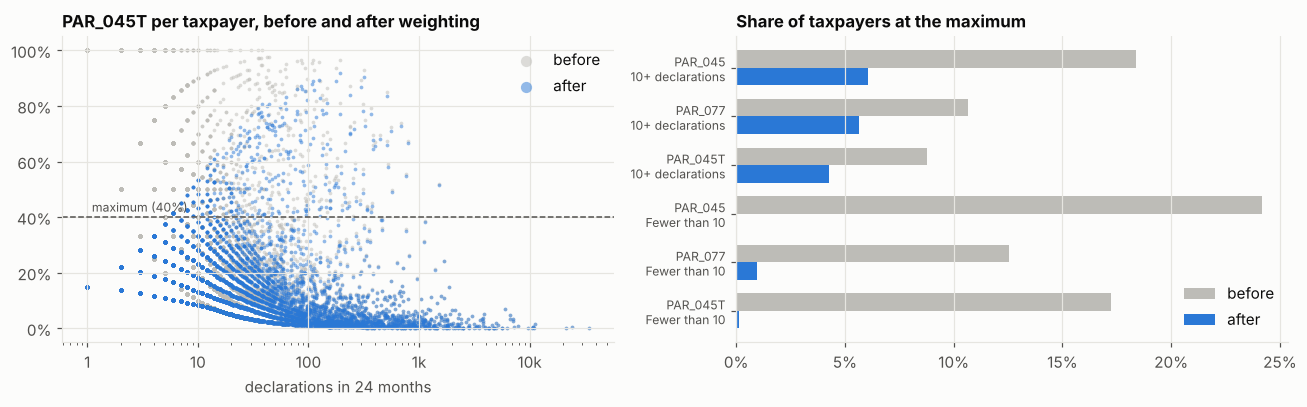

In [14]:
# What: the share of declarations topped up, before and after weighting, by number of declarations.
# Why:  shows the protection working on the people it is meant for.
p = d[d['top_up_entry_rate_raw'] > 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.scatter(p['entries_24m'], p['top_up_entry_rate_raw'], s=6, color=MUTED, alpha=0.5, linewidths=0, label='before')
ax.scatter(p['entries_24m'], p['top_up_entry_rate'], s=6, color=BLUE, alpha=0.5, linewidths=0, label='after')
ax.set_xscale('log'); ax.yaxis.set_major_formatter(pct); ax.xaxis.set_major_formatter(big)
ax.axhline(0.40, color=INK2, linestyle='--', linewidth=1); ax.text(1.1, 0.42, 'maximum (40%)', fontsize=8, color=INK2)
ax.set_xlabel('declarations in 24 months'); ax.set_title('PAR_045T per taxpayer, before and after weighting', fontsize=11)
ax.legend(loc='upper right', markerscale=3)
ax = axes[1]
rows = []
for g in ORDER:
    sub = d[d['group'] == g]
    for p_ in M.PARAMS[:3]:
        rows.append((g, p_['code'], (sub[p_['col'] + '_raw'] >= p_['one_at']).mean(), (sub[p_['col']] >= p_['one_at']).mean()))
t = pd.DataFrame(rows, columns=['group', 'code', 'before', 'after'])
yl = [f"{r.code}\n{r.group}" for r in t.itertuples()]
yy = np.arange(len(t))
ax.barh(yy + 0.18, t['before'], height=0.36, color=MUTED, label='before')
ax.barh(yy - 0.18, t['after'], height=0.36, color=BLUE, label='after')
ax.set_yticks(yy, yl, fontsize=8); ax.xaxis.set_major_formatter(pct); ax.grid(axis='y', visible=False)
ax.set_title('Share of taxpayers at the maximum', fontsize=11); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

### 3.4 Each scored parameter, for taxpayers with 10+ declarations

The dotted line is the concern level (scores 0 below it); the dashed line the maximum (scores full points
from there). The share of taxpayers above each is printed on the panel.

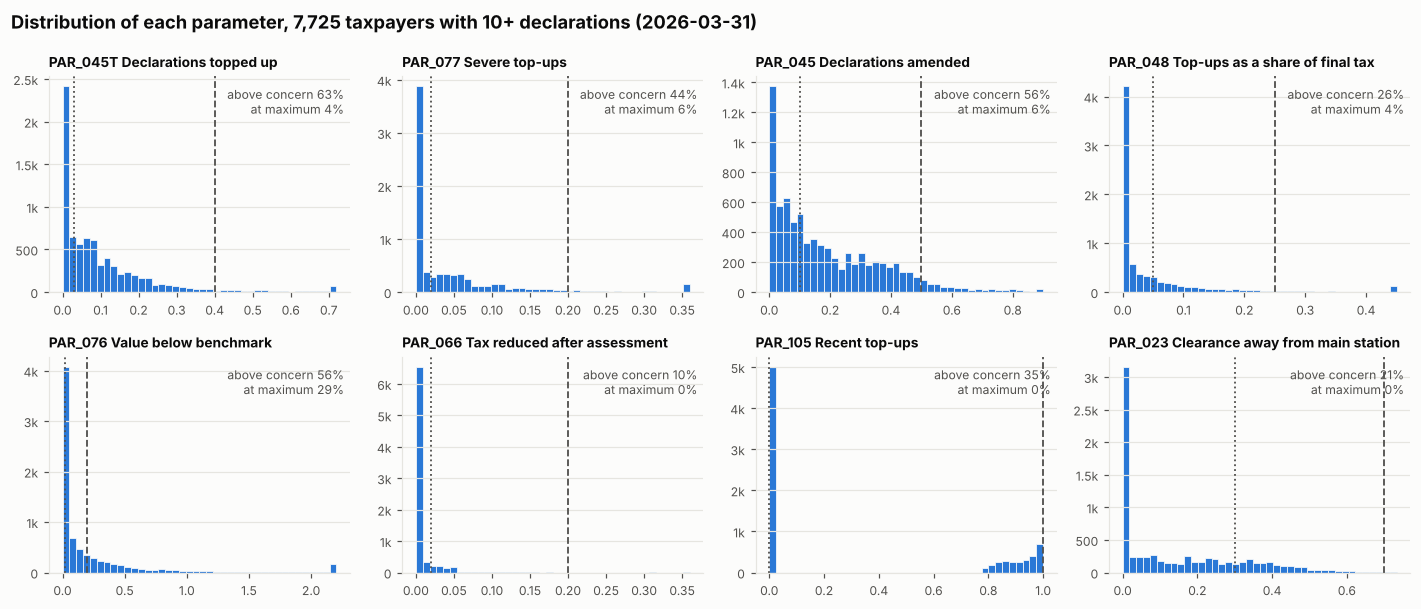

In [15]:
# What: distribution of every scored parameter with its thresholds.  Why: shows how many taxpayers each threshold catches.
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
for ax, p in zip(axes.flat, M.PARAMS):
    x = ad[p['col']].dropna()
    top = max(p['one_at'] * 1.8, x.quantile(0.98))
    ax.hist(x.clip(upper=top), bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
    ax.axvline(p['zero_at'], color=INK2, linestyle=':', linewidth=1.2)
    ax.axvline(p['one_at'], color=INK2, linestyle='--', linewidth=1.2)
    ax.set_title(f"{p['code']} {p['label']}", fontsize=9)
    ax.text(0.98, 0.95, f"above concern {(x > p['zero_at']).mean():.0%}\nat maximum {(x >= p['one_at']).mean():.0%}",
            transform=ax.transAxes, ha='right', va='top', fontsize=8, color=INK2)
    ax.yaxis.set_major_formatter(big); ax.tick_params(labelsize=8); ax.grid(axis='x', visible=False)
fig.suptitle(f'Distribution of each parameter, {len(ad):,} taxpayers with 10+ declarations ({latest})',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

### 3.5 The extreme top-up ratios

PAR_048 divides top-ups by the tax first declared. When that tax is tiny, the ratio explodes: the 4,399 in
the checks was UGX 29 of original tax. Measuring top-ups as a share of the **final** tax gives the same
ordering, is always between 0 and 1, and the officers' thresholds convert exactly (6% of original = 5.7% of
final; 33% of original = 24.8% of final).

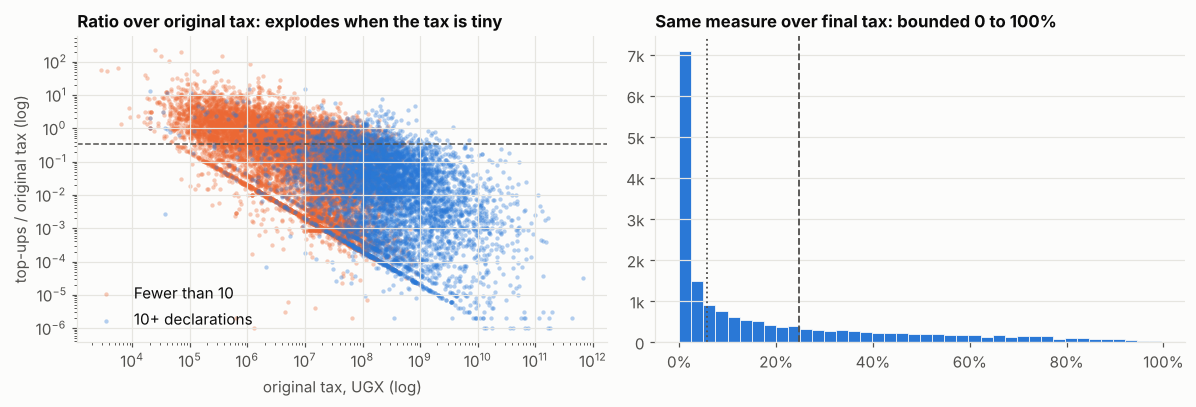

Ratio above 1: 2,318 taxpayers; above 10: 117


In [16]:
# What: the old ratio against original tax, and the same measure over final tax.  Why: the reason for decision 32.
r = d[['par048_top_up_ratio', 'total_original_tax', 'group']].dropna()
r = r[r['par048_top_up_ratio'] > 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for g, colr in zip(ORDER, [ORANGE, BLUE]):
    s_ = r[r['group'] == g]
    axes[0].scatter(s_['total_original_tax'].clip(lower=1), s_['par048_top_up_ratio'], s=8, alpha=0.35, color=colr, label=g, linewidths=0)
axes[0].set_xscale('log'); axes[0].set_yscale('log'); axes[0].axhline(0.33, color=INK2, linestyle='--', linewidth=1)
axes[0].set_xlabel('original tax, UGX (log)'); axes[0].set_ylabel('top-ups / original tax (log)')
axes[0].set_title('Ratio over original tax: explodes when the tax is tiny', fontsize=11); axes[0].legend(loc='lower left')
f = r['par048_top_up_ratio'] / (1 + r['par048_top_up_ratio'])
axes[1].hist(f, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[1].axvline(0.06 / 1.06, color=INK2, linestyle=':', linewidth=1.2); axes[1].axvline(0.33 / 1.33, color=INK2, linestyle='--', linewidth=1.2)
axes[1].xaxis.set_major_formatter(pct); axes[1].yaxis.set_major_formatter(big); axes[1].grid(axis='x', visible=False)
axes[1].set_title('Same measure over final tax: bounded 0 to 100%', fontsize=11)
plt.tight_layout(); plt.show()
print(f"Ratio above 1: {(r['par048_top_up_ratio'] > 1).sum():,} taxpayers; above 10: {(r['par048_top_up_ratio'] > 10).sum():,}")

### 3.6 Do the parameters measure different things?

Spearman correlation between the scored parameters (10+ declarations). Above about 0.7, two parameters are
measuring the same behaviour and would count it twice.

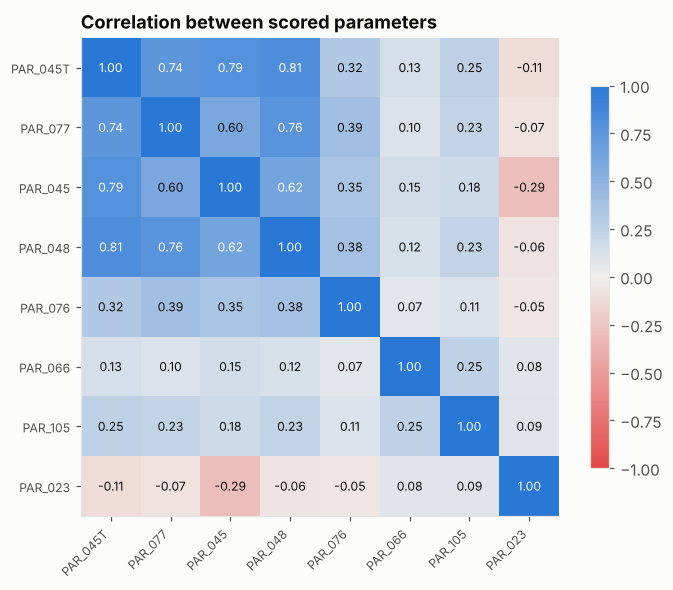

In [17]:
# What: correlation between parameters.  Why: two parameters that move together would double-count one behaviour.
cols = [p['col'] for p in M.PARAMS]
cm = ad[cols].astype(float).corr(method='spearman')
labels = [p['code'] for p in M.PARAMS]
fig, ax = plt.subplots(figsize=(6.6, 5.4))
div = LinearSegmentedColormap.from_list('div', ['#e34948', '#f0efec', BLUE])
im = ax.imshow(cm.values, cmap=div, vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8); ax.grid(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = cm.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 0.6 else INK)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Correlation between scored parameters')
plt.tight_layout(); plt.show()

### 3.7 The 20 agreed parameters: where each one stands

| Status | Parameters |
|---|---|
| **Scored** (8) | PAR_045 amendments, PAR_045 officers' rule (share topped up, PAR_045T), PAR_077, PAR_048, PAR_076, PAR_066, PAR_105, PAR_023 |
| **Built, awaiting Hue** (2) | PAR_067 (price against own history), PAR_053 (exemption and watch-list APC use) |
| **Data not available** (11) | PAR_012, PAR_016, PAR_051, PAR_054, PAR_096 (need earlier declaration versions); PAR_015 (box 45); PAR_039, PAR_040 (penalties); PAR_075 (box 46); PAR_078, PAR_173 (agent TIN) |

Full reasons per parameter are in DECISIONS.md.

### 3.8 What each parameter is worth on its own (Stage 4)

Each parameter alone is used to rank taxpayers. **Lift** = the later hit rate of the top 5% divided by
everyone's, averaged over the six back-test snapshots. 1.0 means no better than picking at random; 4.0 means
the top 5% were topped up four times as often as the average taxpayer. Section 6.1 walks through lift with
real numbers.

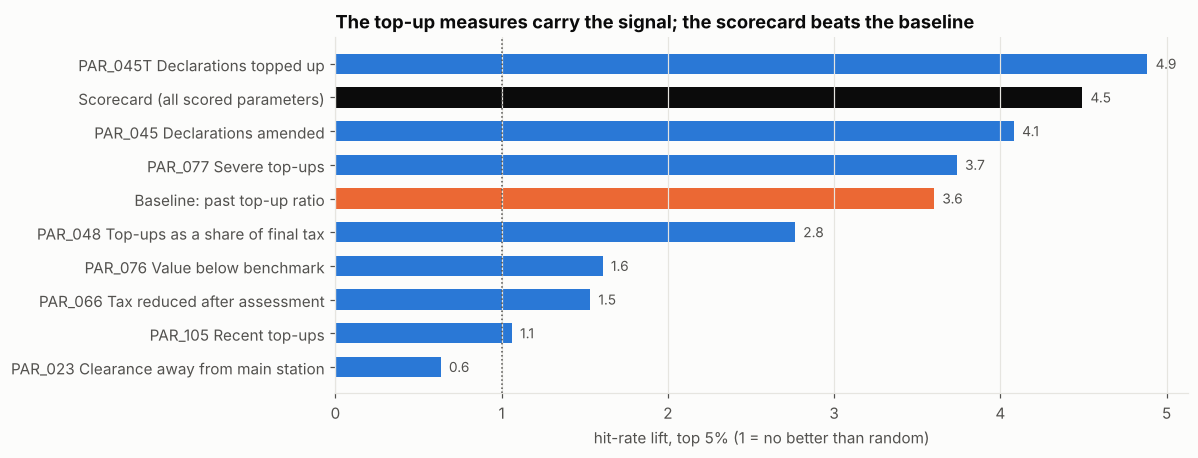

In [18]:
# What: lift at the top 5% for each parameter alone, the baseline and the scorecard.
# Why:  the evidence behind the weights: the parameters that predict later top-ups carry most of the weight.
SUB = {}                                     # scorecard points per snapshot, reused in section 5
rows = []
for snap, raw in ex.items():
    dd = D[snap]
    rows.append(('Baseline: past top-up ratio', lift_at(raw, raw['par048_top_up_ratio'].fillna(0), 0.05)))
    for p in M.PARAMS:
        rows.append((f"{p['code']} {p['label']}", lift_at(raw, dd[p['col']].fillna(0), 0.05)))
    pts, _, _ = M.layer2_scorecard(dd)
    SUB[snap] = pts.sum(axis=1)
    rows.append(('Scorecard (all scored parameters)', lift_at(raw, SUB[snap], 0.05)))
alone = pd.DataFrame(rows, columns=['what', 'lift']).groupby('what')['lift'].mean().sort_values()
fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [ORANGE if w.startswith('Baseline') else (INK if w.startswith('Scorecard') else BLUE) for w in alone.index]
ax.barh(alone.index, alone.values, color=colors, height=0.6)
for i, v in enumerate(alone.values):
    ax.text(v + 0.05, i, f'{v:.1f}', va='center', fontsize=9, color=INK2)
ax.axvline(1, color=INK2, linestyle=':', linewidth=1); ax.grid(axis='y', visible=False)
ax.set_xlabel('hit-rate lift, top 5% (1 = no better than random)')
ax.set_title('The top-up measures carry the signal; the scorecard beats the baseline')
plt.show()

## 4. Peer groups (Stage 5)

A peer group answers: **who is this taxpayer compared with?** It matters for the pattern check (section 5):
"unusual" only means something next to similar traders. Only taxpayers with 10+ declarations get a peer group.

### 4.1 What "main goods x size" means

Two labels, both about **the taxpayer**:

* **Main goods** = the WCO section of the HS chapter where most of the taxpayer's customs value sits over the
  24 months. A taxpayer whose value is mostly HS 87 is in *Vehicles*; mostly HS 52 to 63 is *Textiles*.
* **Size** = the taxpayer's total customs value over the 24 months, compared **only with others in the same
  section**, and cut into thirds: *small* (bottom third), *medium*, *large* (top third).

So *Textiles, large* = a taxpayer who mainly imports textiles and is in the top third of textile importers by
value. Size is relative to the section: a "large" textile importer can be smaller than a "medium" machinery
importer, which is the point, since each is judged against its own trade.

Groups with fewer than 30 taxpayers are too small to compare within, so they are pooled into *Other goods,
small / medium / large* and carry the "no close peers" note.

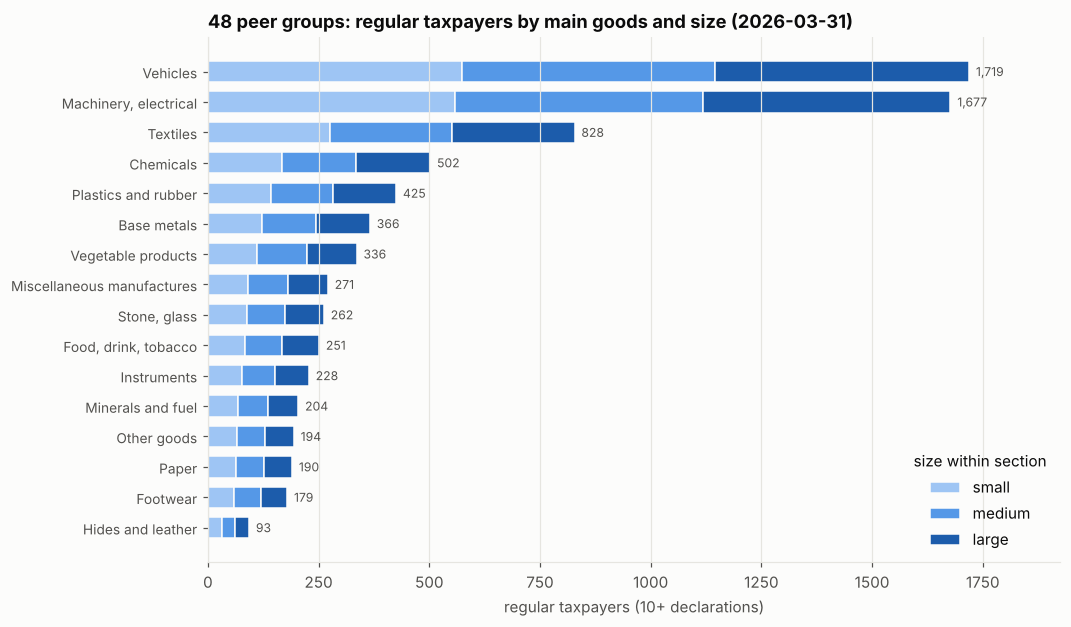

In [19]:
# What: how many regular taxpayers fall in each section and size.  Why: shows the groups an officer would see.
pg = M.peers_section_size(d, [])
pg['section'] = pg['peer_group_name'].str.rsplit(', ', n=1).str[0]
pg['size'] = pg['peer_group_name'].str.rsplit(', ', n=1).str[1]
pg['value'] = d.loc[pg.index, 'total_customs_value']
pg['true_section'] = d.loc[pg.index, 'dominant_hs_chapter'].map(M.hs_section)
tab = pd.crosstab(pg['section'], pg['size']).reindex(columns=['small', 'medium', 'large'])
tab = tab.loc[tab.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(10, 6.2))
left = np.zeros(len(tab))
for sz, colr in zip(['small', 'medium', 'large'], RAMP[1:4]):
    ax.barh(tab.index, tab[sz], left=left, color=colr, label=sz, height=0.7, edgecolor=SURFACE, linewidth=1)
    left += tab[sz].values
for i, v in enumerate(tab.sum(axis=1)):
    ax.text(v, i, f'  {v:,}', va='center', fontsize=8, color=INK2)
ax.grid(axis='y', visible=False); ax.set_xlim(0, tab.sum(axis=1).max() * 1.12)
ax.legend(loc='lower right', title='size within section'); ax.set_xlabel('regular taxpayers (10+ declarations)')
ax.set_title(f'{pg["peer_group_name"].nunique()} peer groups: regular taxpayers by main goods and size ({latest})')
ax.tick_params(axis='y', labelsize=9)
plt.show()

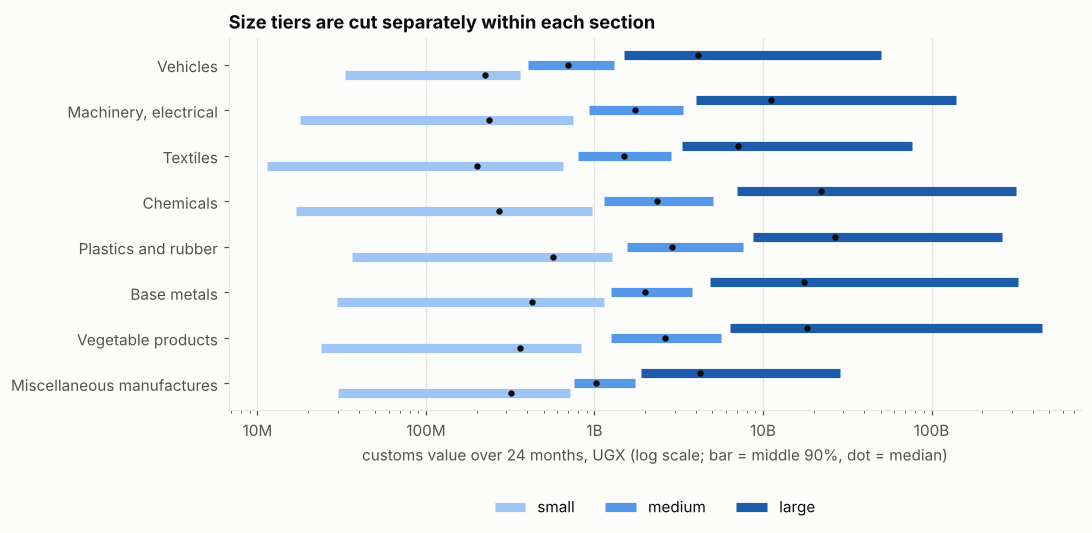

In [20]:
# What: the customs-value range of each size tier, for the largest sections.
# Why:  shows that "large" means large FOR THAT TRADE, not large overall.
top_secs = pg['true_section'].value_counts().head(8).index[::-1]
fig, ax = plt.subplots(figsize=(10, 4.4))
for i, sec in enumerate(top_secs):
    sub = pg[pg['true_section'] == sec]
    for k, (sz, colr) in enumerate(zip(['small', 'medium', 'large'], RAMP[1:4])):
        v = sub.loc[sub['size'] == sz, 'value']
        if len(v):
            y = i + (k - 1) * 0.22
            ax.plot([v.quantile(0.05), v.quantile(0.95)], [y, y], color=colr, linewidth=6, solid_capstyle='butt',
                    label=sz if i == 0 else None)
            ax.scatter(v.median(), y, color=INK, s=10, zorder=3)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(big)
ax.set_yticks(range(len(top_secs)), top_secs); ax.grid(axis='y', visible=False)
ax.set_xlabel('customs value over 24 months, UGX (log scale; bar = middle 90%, dot = median)')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.32), ncol=3)
ax.set_title('Size tiers are cut separately within each section')
plt.show()

### 4.2 Why the data-driven method (HDBSCAN) left 77% of taxpayers unclustered

**What HDBSCAN does.** Picture every taxpayer as a dot on a map, placed by its nine trading measures
(value, declarations, months active, items per declaration, HS headings, origins, CPCs, stations, share of
value in the main chapter). HDBSCAN looks for **crowded neighbourhoods**: for each dot it measures how far
it has to reach to touch its 10 nearest neighbours (`min_samples = 10`). A short reach means a crowded spot;
a long reach means a thin one. It then keeps only crowded spots holding at least 50 dots
(`min_cluster_size = 50`) as groups. Every dot in a thin area is labelled **noise** (unclustered). It never
forces a dot into a group: that is its strength for finding real clumps, and its weakness here.

**Why most taxpayers end up as noise in our data.** The toy example below shows the difference.
On the left, data made of real clumps: HDBSCAN finds them and leaves little noise. On the right, data like
ours: one long, smooth spread with a few piles where many dots sit on exactly the same values. HDBSCAN finds
only the piles and calls the rest noise.

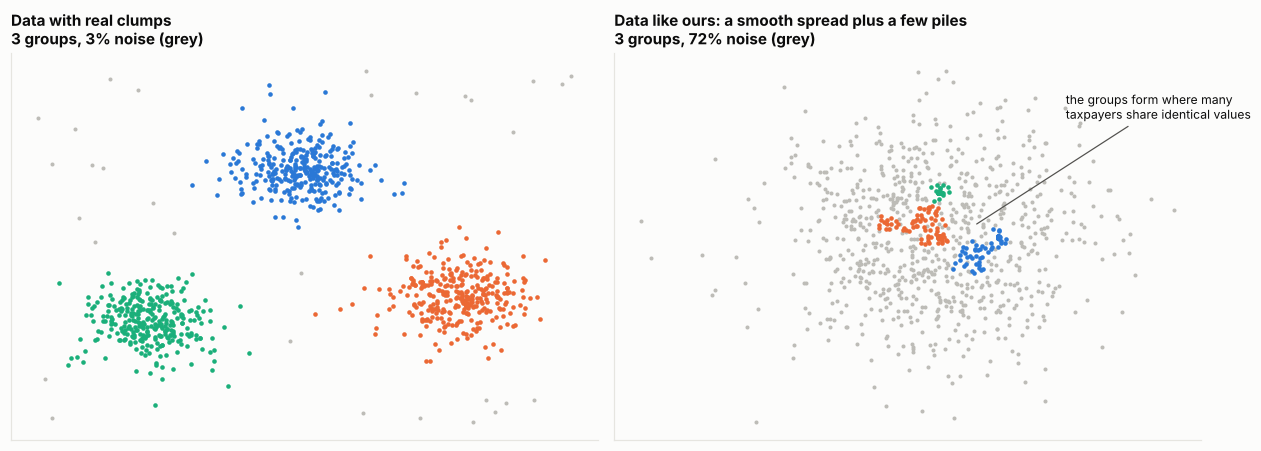

In [21]:
# What: HDBSCAN on two made-up datasets.  Why: to see how it behaves before looking at the real result.
from sklearn.cluster import HDBSCAN
from sklearn.datasets import make_blobs
rng = np.random.default_rng(0)
A, _ = make_blobs(n_samples=900, centers=[(-4, -3), (0, 3), (4, -2)], cluster_std=0.8, random_state=1)
A = np.vstack([A, rng.uniform(-7, 7, size=(60, 2))])
cont = np.column_stack([rng.lognormal(0, 0.9, 900), rng.lognormal(0, 0.9, 900)])   # one smooth, skewed spread
piles = np.vstack([np.tile([[1, 1]], (60, 1)), np.tile([[2, 1]], (60, 1)), np.tile([[1, 2]], (60, 1))]) \
        + rng.normal(0, 0.01, (180, 2))                                             # many taxpayers on identical values
B = np.log(np.vstack([cont, piles]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, X_, title in [(axes[0], A, 'Data with real clumps'), (axes[1], B, 'Data like ours: a smooth spread plus a few piles')]:
    lab = HDBSCAN(min_cluster_size=50, min_samples=10).fit_predict(X_)
    ax.scatter(X_[lab == -1, 0], X_[lab == -1, 1], s=7, color=MUTED, linewidths=0, label='noise')
    for k, colr in zip(sorted(set(lab) - {-1}), [BLUE, ORANGE, AQUA, '#7d58c4', '#d9a32b']):
        ax.scatter(X_[lab == k, 0], X_[lab == k, 1], s=9, color=colr, linewidths=0)
    ax.set_title(f'{title}\n{len(set(lab)) - (-1 in lab)} groups, {(lab == -1).mean():.0%} noise (grey)', fontsize=10)
    if X_ is B:
        ax.annotate('the groups form where many\ntaxpayers share identical values', (np.log(1.5), np.log(1.2)),
                    xytext=(60, 70), textcoords='offset points', fontsize=8, color=INK, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Four things about our nine measures push the real data into the right-hand picture:

1. **Trade is a continuum, not types.** Taxpayers do not come in separate kinds by size or spread of goods:
   there is a smooth run from tiny to huge. A density method has no gap to cut along.
2. **Counts create artificial piles.** HS headings, origins, CPCs and stations are small whole numbers. Hundreds
   of taxpayers sit on exactly "1 heading, 1 origin, 1 item per declaration". Those piles are the densest spots,
   so they become the groups, and they are groups of *vehicle and fuel importers with one product*, not
   meaningful peer sets.
3. **Nine dimensions thin everything out.** The more measures, the further apart dots are, so fewer
   neighbourhoods look crowded (often called the curse of dimensionality).
4. **The settings ask for crowded areas.** 50 dots, each with 10 close neighbours. Lowering them only moves noise
   from 77% to about 70% (tested: 10 to 50 and 5 to 10), so the settings are not the main cause.

The real result, drawn on the two directions that capture the most spread (PCA, about 74% of it):

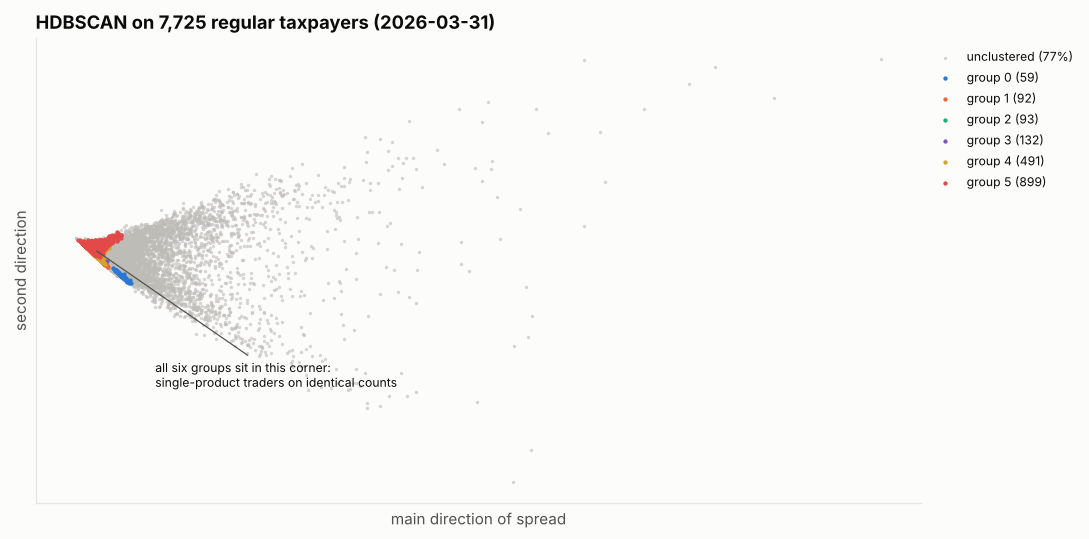

,taxpayers,main_chapter,hs_headings,origins,items_per_declaration,value_in_main_chapter
group,,,,,,
group 0,59,27,1,9,1.0,100%
group 1,92,87,3,1,1.0,100%
group 2,93,87,2,2,1.0,100%
group 3,132,63,2,1,1.0,100%
group 4,491,87,2,1,1.0,100%
group 5,899,87,2,1,1.1,100%
unclustered,5959,84,18,3,2.8,66%


In [22]:
# What: HDBSCAN on the real regular taxpayers, drawn in 2D, and what each group is.
# Why:  shows that the groups are piles of single-product traders, and everything else is noise.
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
X = ad[M.PEER_FEATURES].fillna(ad[M.PEER_FEATURES].median())
Xs = RobustScaler().fit_transform(X)
lab = HDBSCAN(min_cluster_size=50, min_samples=10).fit_predict(Xs)
xy = PCA(2, random_state=M.SEED).fit_transform(Xs)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(xy[lab == -1, 0], xy[lab == -1, 1], s=5, color=MUTED, linewidths=0, alpha=0.6, label=f'unclustered ({(lab == -1).mean():.0%})')
for k, colr in zip(sorted(set(lab) - {-1}), [BLUE, ORANGE, AQUA, '#7d58c4', '#d9a32b', '#e34948']):
    ax.scatter(xy[lab == k, 0], xy[lab == k, 1], s=8, color=colr, linewidths=0, label=f'group {k} ({(lab == k).sum()})')
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel('main direction of spread'); ax.set_ylabel('second direction')
ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), fontsize=8)
ax.annotate('all six groups sit in this corner:\nsingle-product traders on identical counts', xy[lab >= 0].mean(axis=0),
            xytext=(40, -90), textcoords='offset points', fontsize=8, color=INK, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.set_title(f'HDBSCAN on {len(ad):,} regular taxpayers ({latest})')
plt.tight_layout(); plt.show()

prof = X.assign(group=np.where(lab == -1, 'unclustered', 'group ' + pd.Series(lab).astype(str).values),
                chapter=ad['dominant_hs_chapter'].values)
summary = prof.groupby('group').agg(
    taxpayers=('log_value', 'size'),
    main_chapter=('chapter', lambda s: int(s.mode().iloc[0])),
    hs_headings=('hs_headings_used', 'median'), origins=('origins_used', 'median'),
    items_per_declaration=('avg_items_per_entry', 'median'), value_in_main_chapter=('chapter_value_share', 'median'))
summary.style.format({'value_in_main_chapter': '{:.0%}', 'items_per_declaration': '{:.1f}', 'hs_headings': '{:.0f}', 'origins': '{:.0f}'})

### 4.3 The two methods side by side

| | HDBSCAN (data-driven) | Main goods x size (adopted) |
|---|---|---|
| Groups | 6 | 48 |
| Regular taxpayers without a real group | 77% (sent to the nearest group) | 2.5% (pooled into "Other goods") |
| What a group means | A pile of single-product traders | Named trade and size, e.g. *Vehicles, large* |
| Can an officer explain it? | Hard | Yes |
| Changes with settings | Yes, noticeably | Only the 30-taxpayer pooling rule |

Main goods x size was adopted (decision 44) because nearly everyone gets a real group and an officer can say
in one line who a taxpayer was compared with. HDBSCAN was then removed from the model code (decision 45); this
section is the record of why.

## 5. The pattern check (Stage 6): what it is, and whether it earns its points

### 5.1 The idea in plain words

The scorecard looks at **one measure at a time**: is the share topped up above 3%? Is the amendment rate above
10%? The pattern check looks at **the whole profile at once** and asks: *compared with the other taxpayers in
the same peer group, how odd is this taxpayer's combination of measures?* It is meant to catch someone whose
measures are each just under their thresholds but together look strange.

### 5.2 How the Isolation Forest measures "odd"

Imagine trying to single out one taxpayer from their peer group by asking random yes/no questions, each one
a random cut on a random measure ("more than 40 HS headings?", "IM7 share above 0.3?").

* A **typical** taxpayer sits among many similar ones, so it takes **many cuts** to separate them.
* An **odd** taxpayer sits apart, so **a few cuts** isolate them.

The forest repeats this with 200 random sets of cuts and averages. Fewer cuts on average = more unusual.
Each taxpayer then gets a **percentile within their peer group**: 0.95 means more unusual than 95% of peers.
The rule we TESTED: taxpayers above the 80th percentile earn points on a straight line, up to 15 points at
the 100th percentile (halved for pooled groups). Section 5.6 records why that rule was replaced by a note.

Important: the forest has **no idea what risk is**. It never sees outcomes. It only finds what is rare.
Rare can mean risky, or it can mean a big, complex, perfectly honest importer.

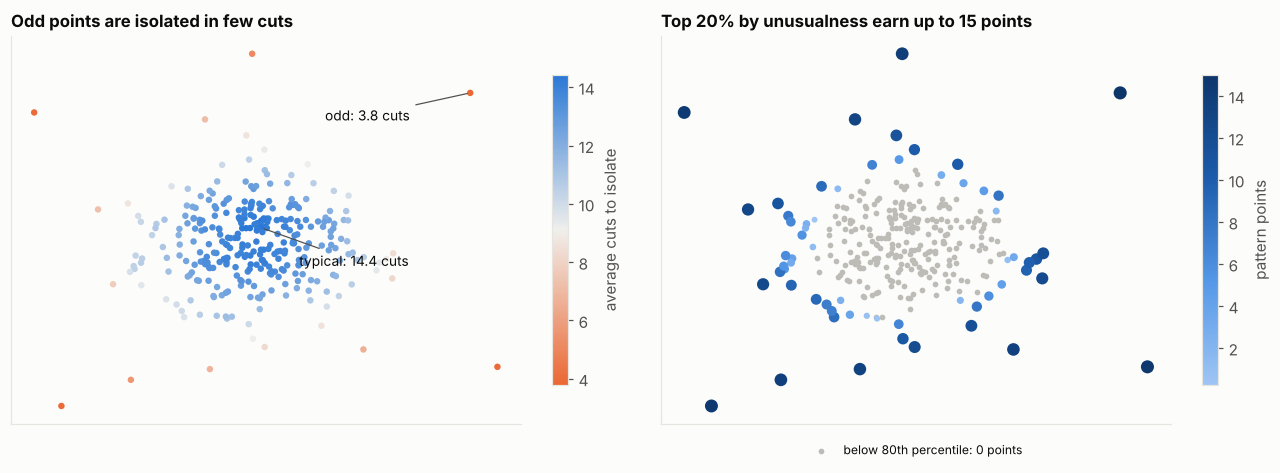

In [23]:
# What: an Isolation Forest on a made-up cloud of 300 taxpayers with a few odd ones.
# Why:  to see "few cuts = unusual" before using it on real data.
from sklearn.ensemble import IsolationForest
rng = np.random.default_rng(3)
T = np.vstack([rng.normal(0, 1, (300, 2)), [[4, 4], [-4, 3.5], [4.5, -3], [0, 5], [-3.5, -4]]])
forest = IsolationForest(n_estimators=200, random_state=M.SEED).fit(T)
odd = -forest.score_samples(T)                       # higher = more unusual
c = 2 * (np.log(255) + 0.5772) - 2 * 255 / 256         # average cuts for a typical point (256-sample trees)
cuts = -np.log2(odd) * c                               # average number of cuts to isolate each point
pctl = pd.Series(odd).rank(pct=True).values
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
sc_ = ax.scatter(T[:, 0], T[:, 1], c=cuts, cmap=LinearSegmentedColormap.from_list('c', [ORANGE, '#f0efec', BLUE]), s=18, linewidths=0)
i_typ, i_odd = int(np.argmax(cuts)), 300
for i, txt in [(i_typ, 'typical'), (i_odd, 'odd')]:
    ax.annotate(f'{txt}: {cuts[i]:.1f} cuts', T[i], xytext=(25, -25) if txt == 'typical' else (-95, -18), textcoords='offset points',
                fontsize=9, color=INK, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
fig.colorbar(sc_, ax=ax, shrink=0.8, label='average cuts to isolate')
ax.set_title('Odd points are isolated in few cuts', fontsize=11); ax.set_xticks([]); ax.set_yticks([])
ax = axes[1]
top = pctl > 0.80
ax.scatter(T[~top, 0], T[~top, 1], s=14, color=MUTED, linewidths=0, label='below 80th percentile: 0 points')
pts_ = ((pctl[top] - 0.8) / 0.2) * 15
s2 = ax.scatter(T[top, 0], T[top, 1], s=14 + pts_ * 4, c=pts_, cmap=LinearSegmentedColormap.from_list('p', RAMP[1:]), linewidths=0)
fig.colorbar(s2, ax=ax, shrink=0.8, label='pattern points')
ax.set_title('Top 20% by unusualness earn up to 15 points', fontsize=11); ax.set_xticks([]); ax.set_yticks([])
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.02), fontsize=8)
plt.tight_layout(); plt.show()

### 5.3 Who it flags in our data

The most unusual 10% of regular taxpayers in the latest snapshot, against the usual half. Each bar shows how
many times larger the unusual group's median is.

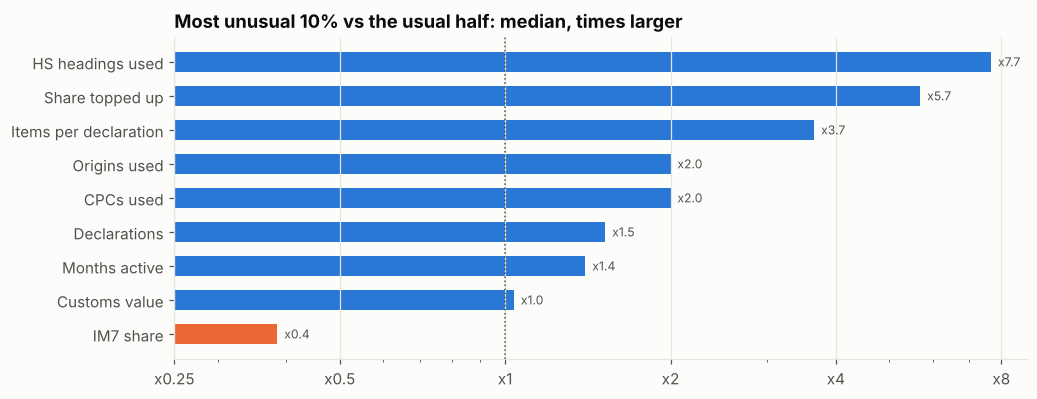

In [24]:
# What: run the peer groups and pattern check for every snapshot, then profile the most unusual taxpayers.
# Why:  to see WHAT the forest is reacting to in real data.
def tested_points(pctl_, peers, dd):
    # the rule tested in Stage 6: 0 points at the 80th percentile, 15 at the 100th, halved for pooled groups
    pts = ((pctl_ - 0.8) / 0.2).clip(0, 1).fillna(0) * 15
    pooled = peers['no_close_peers'].reindex(dd.index).eq('Y')
    return pts.where(~pooled, pts * 0.5)

PAT = {}
for snap in ex:
    dd = D[snap]
    peers = M.layer1_peers(dd, [])
    pctl_, low = M.layer3_pattern(dd, peers, SUB[snap])
    PAT[snap] = dict(adj=tested_points(pctl_, peers, dd), pct=pctl_)
pl = PAT[latest]['pct']
unusual = d['adequate'] & (pl >= 0.9)
usual = d['adequate'] & (pl < 0.5)
feat = {'hs_headings_used': 'HS headings used', 'avg_items_per_entry': 'Items per declaration',
        'top_up_entry_rate_raw': 'Share topped up', 'origins_used': 'Origins used', 'cpcs_used': 'CPCs used',
        'entries_24m': 'Declarations', 'active_months': 'Months active', 'total_customs_value': 'Customs value',
        'im7_share': 'IM7 share'}
ratio = pd.Series({lbl: (d.loc[unusual, c].median() + 1e-9) / (d.loc[usual, c].median() + 1e-9) for c, lbl in feat.items()}).sort_values()
fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.barh(ratio.index, ratio.values, color=[BLUE if v >= 1 else ORANGE for v in ratio.values], height=0.6)
for b, v in zip(bars, ratio.values):
    ax.text(v, b.get_y() + b.get_height() / 2, f'  x{v:.1f}', va='center', fontsize=8, color=INK2)
ax.set_xscale('log'); ax.axvline(1, color=INK2, linestyle=':', linewidth=1); ax.grid(axis='y', visible=False)
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8]); ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: f'x{v:g}'))
ax.xaxis.set_minor_formatter(mt.NullFormatter())
ax.set_title('Most unusual 10% vs the usual half: median, times larger')
plt.show()

The forest mostly reacts to **variety**: many HS headings, many items per declaration, many origins. These are
general merchants and consolidators. It also picks up a higher share topped up, but the scorecard already
scores that directly.

### 5.4 Does it find risk the scorecard misses?

This is the real test. Split regular taxpayers by the scorecard (under 15 points = scorecard sees little;
15+ = scorecard already concerned) and by the pattern check (unusual = top 20% of their group). Then look at
the hit rate in the 6 months after, averaged over the six snapshots.

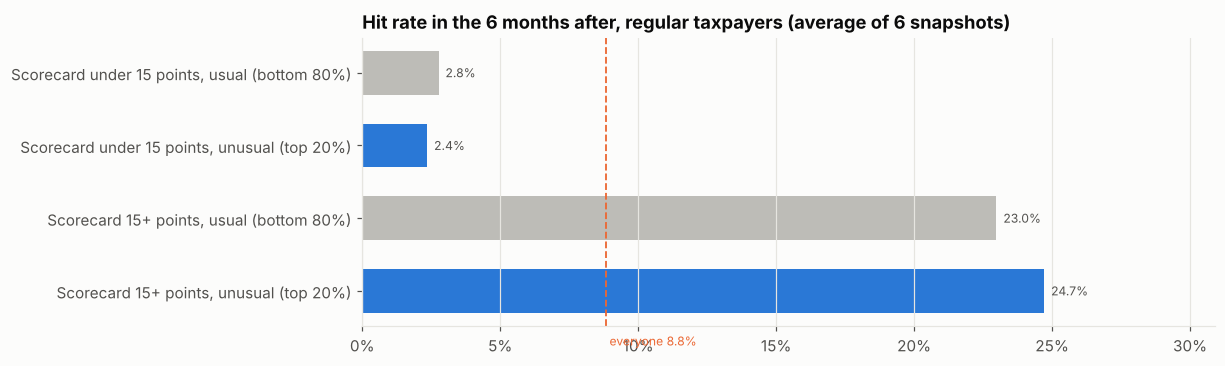

In [25]:
# What: later hit rate for scorecard-low/high x usual/unusual.  Why: the pattern check only adds value if
#       the "scorecard low but unusual" group is hit more often than "scorecard low and usual".
rows = []
for snap, raw in ex.items():
    dd, sub, pc = D[snap], SUB[snap], PAT[snap]['pct']
    reg = dd['adequate']
    for sc_lbl, sc_mask in [('Scorecard under 15 points', sub < 15), ('Scorecard 15+ points', sub >= 15)]:
        for p_lbl, p_mask in [('usual (bottom 80%)', pc < 0.8), ('unusual (top 20%)', pc >= 0.8)]:
            rows.append(dict(snap=snap, scorecard=sc_lbl, pattern=p_lbl, hr=hit_rate(raw[reg & sc_mask & p_mask]),
                             n=int((reg & sc_mask & p_mask).sum())))
    rows.append(dict(snap=snap, scorecard='Everyone', pattern='all', hr=hit_rate(raw), n=len(raw)))
hr = pd.DataFrame(rows)
avg = hr.groupby(['scorecard', 'pattern'])[['hr', 'n']].mean()
base_hr = avg.loc[('Everyone', 'all'), 'hr']
fig, ax = plt.subplots(figsize=(10, 3.4))
labels_, vals_, cols_ = [], [], []
for sc_lbl in ['Scorecard under 15 points', 'Scorecard 15+ points']:
    for p_lbl, colr in [('usual (bottom 80%)', MUTED), ('unusual (top 20%)', BLUE)]:
        labels_.append(f'{sc_lbl}, {p_lbl}'); vals_.append(avg.loc[(sc_lbl, p_lbl), 'hr']); cols_.append(colr)
bars = ax.barh(labels_[::-1], vals_[::-1], color=cols_[::-1], height=0.6)
bar_labels(ax, bars, fmt='{:.1%}')
ax.axvline(base_hr, color=ORANGE, linestyle='--', linewidth=1.2)
ax.text(base_hr, -0.75, f' everyone {base_hr:.1%}', color=ORANGE, fontsize=8)
ax.xaxis.set_major_formatter(pct); ax.grid(axis='y', visible=False); ax.set_xlim(0, max(vals_) * 1.25)
ax.set_title('Hit rate in the 6 months after, regular taxpayers (average of 6 snapshots)')
plt.show()

**Reading the chart.** Among taxpayers the scorecard sees as low risk, the "unusual" ones are hit **no more
often** than the usual ones. So the pattern check is not finding hidden top-up risk. Where the scorecard is
already concerned, being unusual adds only a little. That is why adding pattern points lowers the lift a
little: the 15 points lift general merchants up the list, ahead of taxpayers with a worse top-up record.

**One honest caveat.** The outcome we test against is narrow: a top-up on a red or yellow declaration. The
pattern check might be picking up risks this outcome cannot see (for example, valuation that is never checked,
or a new scheme). We cannot prove that with the data we have, and we should say so.

### 5.5 The options, tested

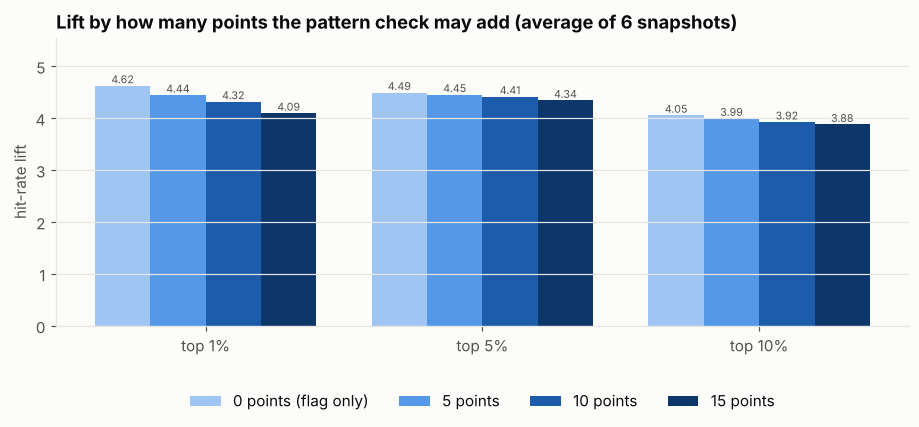

cap,0,5,10,15
share,,,,
top 1%,4.62,4.44,4.32,4.09
top 5%,4.49,4.45,4.41,4.34
top 10%,4.05,3.99,3.92,3.88


In [26]:
# What: lift of the full model with the pattern check worth 0, 5, 10 or 15 points.
# Why:  the decision for Stage 6, in numbers.
rows = []
for snap, raw in ex.items():
    for cap in [0, 5, 10, 15]:
        key = SUB[snap] + PAT[snap]['adj'] / 15 * cap
        for share in [0.01, 0.05, 0.10]:
            rows.append(dict(cap=cap, share=share, lift=lift_at(raw, key, share)))
opt = pd.DataFrame(rows).groupby(['share', 'cap'])['lift'].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 3.4))
w = 0.2
for k, (cap, colr) in enumerate(zip([0, 5, 10, 15], RAMP[1:] )):
    xs_ = np.arange(3) + (k - 1.5) * w
    b = ax.bar(xs_, opt[cap].values, width=w, color=colr, label=f'{cap} points' + (' (flag only)' if cap == 0 else ''))
    for xx, v in zip(xs_, opt[cap].values):
        ax.text(xx, v, f'{v:.2f}', ha='center', va='bottom', fontsize=7, color=INK2)
ax.set_xticks(range(3), [f'top {s:.0%}' for s in opt.index]); ax.set_ylim(0, opt.values.max() * 1.2)
ax.grid(axis='x', visible=False); ax.set_ylabel('hit-rate lift')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.34), ncol=4, title=None)
ax.set_title('Lift by how many points the pattern check may add (average of 6 snapshots)')
plt.show()
opt.rename(index=lambda s: f'top {s:.0%}').style.format('{:.2f}')

### 5.6 Decision: a note, no points (decision 46)

| Option | What the officer sees | Evidence |
|---|---|---|
| **A. Note only, 0 points** (chosen) | Score from the scorecard alone; an "unusual trading pattern" note beside it | Best lift at every cut-off; every point stays tied to an agreed parameter |
| B. Up to 5 points | Small nudge | Slightly lower lift |
| C. Keep 15 points | As tested | Lowest lift; moves about 360 taxpayers per snapshot into a different band |

The note is written when a taxpayer is more unusual than **95%** of their peer group (about 400 taxpayers per
snapshot). The 80th percentile used for points would put a note on 1 in 5 regular traders, too many to be read.

**Why A.** The pattern check does not find extra top-up risk (5.4), and its points push complex but clean
traders up the list. Keeping it as a note costs nothing in ranking and still tells the officer "this one trades
oddly for their group", which is what the Risk Officers asked for when they said everyone should be scored but
some things should simply be brought to their attention. It can earn points again later if PCA or audit
results show that unusual taxpayers do carry risk the top-up outcome misses.

## 6. Scoring the latest back-test snapshot

The full model on current settings (version 1.0.0-dev4: the pattern check is a note, no points). The output
workbook has a fixed layout (see `src/ctrp/report.py`): Scores, Reasons, Parameter values, Band summary, Reason
codes and Run info.

In [27]:
# What: score the latest back-test snapshot.  Why: everything below in this section reads from this result.
res = M.score_snapshot(ex[latest])
print('\n'.join(res.log)); print(f'model {res.version}, settings fingerprint {res.fingerprint}')
sc = res.scores
bands = [b for _, b in M.BANDS]

Snapshot 2026-03-31: 58,161 taxpayers, 7,725 with 10+ declarations
Peer groups by HS section x size: 48 groups; 2.5% pooled into 'Other goods'
model 1.0.0-dev4, settings fingerprint 7fe30342ff


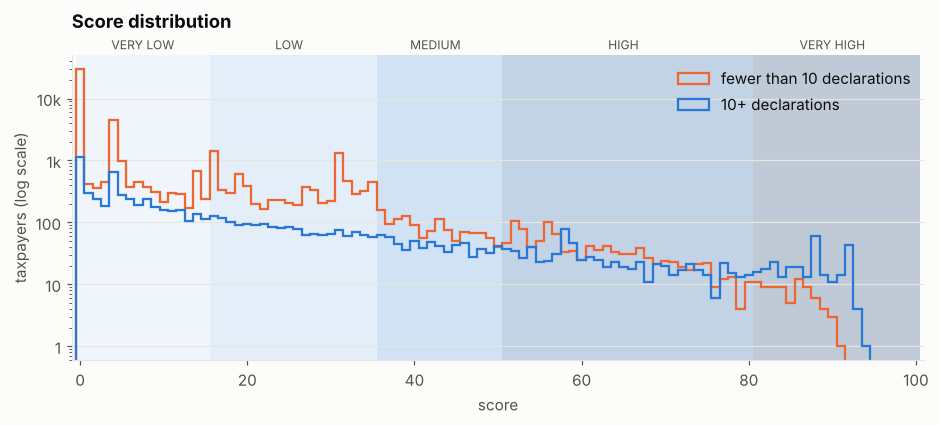

In [28]:
# What: how scores are spread, with the band cut-offs.  Why: Stage 7 sets the bands against this shape.
fig, ax = plt.subplots(figsize=(10, 3.6))
edges = [0] + [hi for hi, _ in M.BANDS]
for (lo, hi), b, colr in zip(zip(edges[:-1], edges[1:]), bands, RAMP):
    ax.axvspan(lo - 0.5 if lo == 0 else lo + 0.5, hi + 0.5, color=colr, alpha=0.25, linewidth=0)
    ax.text((lo + hi) / 2, 1.02, b, transform=ax.get_xaxis_transform(), ha='center', fontsize=8, color=INK2)
for g, colr in zip(['Y', 'N'], [ORANGE, BLUE]):
    v = sc.loc[sc['flag_limited_history'] == g, 'score']
    ax.hist(v, bins=np.arange(-0.5, 101.5, 1), histtype='step', color=colr, linewidth=1.5,
            label='fewer than 10 declarations' if g == 'Y' else '10+ declarations')
ax.set_yscale('log'); ax.yaxis.set_major_formatter(big); ax.set_xlim(-1, 101); ax.grid(axis='x', visible=False)
ax.set_xlabel('score'); ax.set_ylabel('taxpayers (log scale)')
ax.legend(loc='upper right')
ax.set_title('Score distribution', pad=18)
plt.show()

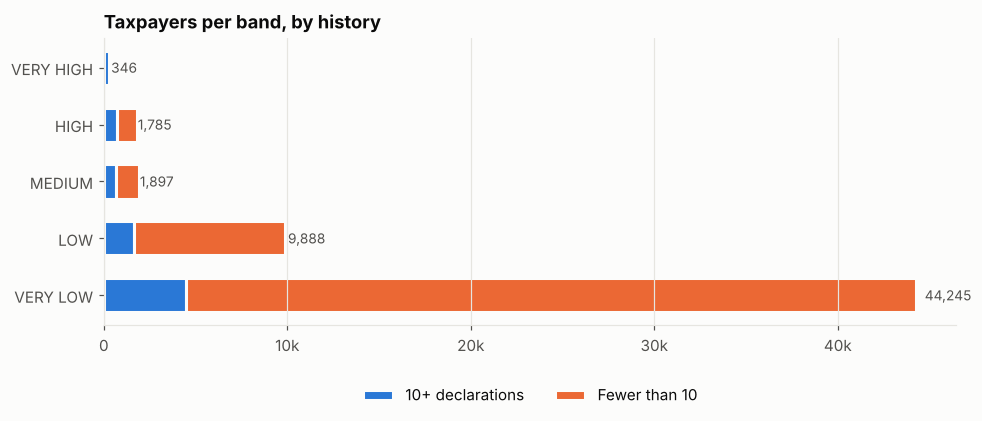

In [29]:
# What: taxpayers per band, split by history.  Why: shows the workload each band would create.
tab = pd.crosstab(sc['band'], sc['flag_limited_history']).reindex(bands).fillna(0)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.barh(bands, tab['N'], color=BLUE, label='10+ declarations', height=0.6, edgecolor=SURFACE, linewidth=2)
ax.barh(bands, tab['Y'], left=tab['N'], color=ORANGE, label='Fewer than 10', height=0.6, edgecolor=SURFACE, linewidth=2)
for i, b in enumerate(bands):
    ax.text(tab.loc[b].sum() * 1.01 + 50, i, f"{int(tab.loc[b].sum()):,}", va='center', fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(big); ax.grid(axis='y', visible=False)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.32), ncol=2)
ax.set_title('Taxpayers per band, by history')
plt.show()

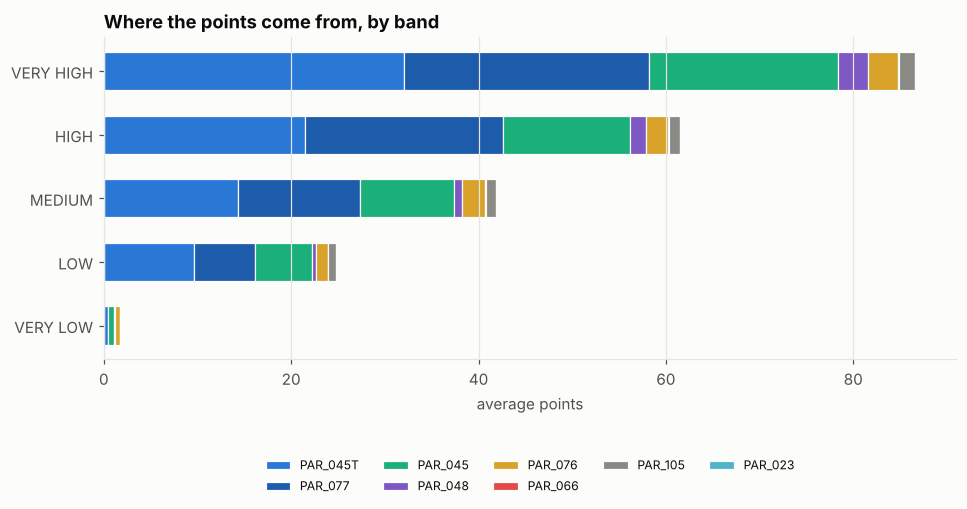

In [30]:
# What: average points from each parameter, per band.  Why: shows what drives each band.
pv = res.params.merge(sc[['taxpayer_tin', 'band']], on='taxpayer_tin')
pcols = [c for c in pv if c.startswith('points_')]
contrib = pv.groupby('band')[pcols].mean().reindex(bands)
contrib.columns = [c.replace('points_', '') for c in pcols]
palette = [BLUE, '#1c5cab', AQUA, '#7d58c4', '#d9a32b', '#e34948', '#8a8984', '#4fb3c9']
fig, ax = plt.subplots(figsize=(10, 3.8))
left = np.zeros(len(contrib))
for col, colr in zip(contrib.columns, palette):
    ax.barh(bands, contrib[col], left=left, color=colr, label=col, height=0.6, edgecolor=SURFACE, linewidth=0.8)
    left += contrib[col].fillna(0).values
ax.grid(axis='y', visible=False); ax.set_xlabel('average points')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.45), ncol=5, fontsize=8)
ax.set_title('Where the points come from, by band')
plt.show()

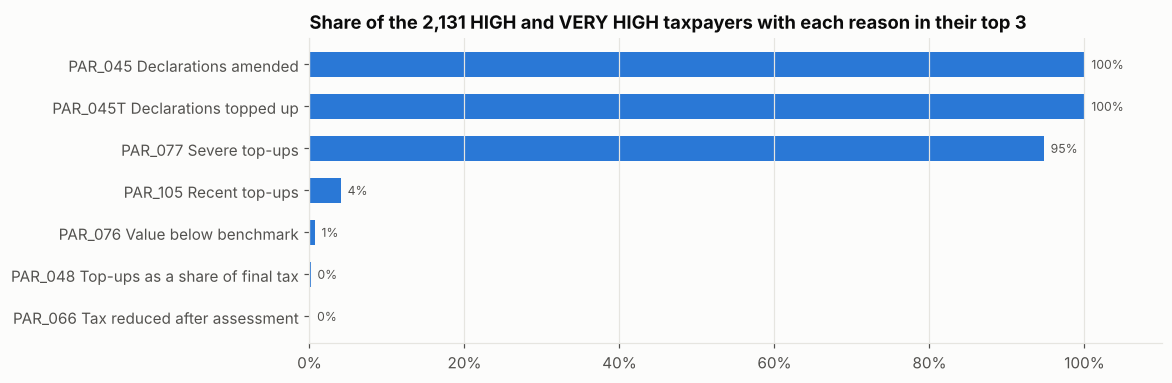

Unusual-pattern notes (no points): 413 taxpayers, of whom 223 are HIGH or VERY HIGH


In [31]:
# What: how often each reason appears in the top 3 for HIGH and VERY HIGH taxpayers.
# Why:  what officers will read most; checks that no single reason dominates by accident.
hi = res.reasons[res.reasons['band'].isin(['HIGH', 'VERY HIGH']) & (res.reasons['order'] <= 3)]
n_hi = sc['band'].isin(['HIGH', 'VERY HIGH']).sum()
freq = (hi.groupby(['code', 'label']).size() / n_hi).sort_values()
fig, ax = plt.subplots(figsize=(10, 3.6))
bars = ax.barh([f'{c} {l}' for c, l in freq.index], freq.values, color=BLUE, height=0.6)
bar_labels(ax, bars, fmt='{:.0%}')
ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, 1.1); ax.grid(axis='y', visible=False)
ax.set_title(f'Share of the {n_hi:,} HIGH and VERY HIGH taxpayers with each reason in their top 3')
plt.show()
print(f"Unusual-pattern notes (no points): {(sc['flag_unusual_pattern'] == 'Y').sum():,} taxpayers, "
      f"of whom {((sc['flag_unusual_pattern'] == 'Y') & sc['band'].isin(['HIGH', 'VERY HIGH'])).sum():,} are HIGH or VERY HIGH")

### 6.1 What lift means, with this snapshot's real numbers

1. **Everyone.** In the 6 months after 31 March 2026, customs checked (red or yellow) 182,868 declarations from
   these taxpayers and 12,726 ended in a top-up. Hit rate for everyone: 12,726 / 182,868 = **7.0%**. If officers
   picked declarations at random, about 7 checks in 100 would find a top-up.
2. **The top of the list.** The model's top 5% is 2,908 taxpayers. Their declarations got 19,134 checks and
   7,162 ended in a top-up. Their hit rate: **37.4%**, about 37 top-ups per 100 checks.
3. **Lift** = 37.4% / 7.0% = **5.4**. Checking the top of the list finds top-ups 5.4 times as often as checking at
   random. Lift 1 means the list is no better than chance.
4. **Why it matters.** Officers can only check a small share of declarations. Lift says how much more each
   check finds when they follow the list. And here, those 2,908 taxpayers (5% of the list) produced 7,162 of all
   12,726 hits: **56% of all hits**.

The two charts below show the same idea for the whole list: the hit rate in each tenth of the ranking, and how
quickly the hits pile up as you go down the list.

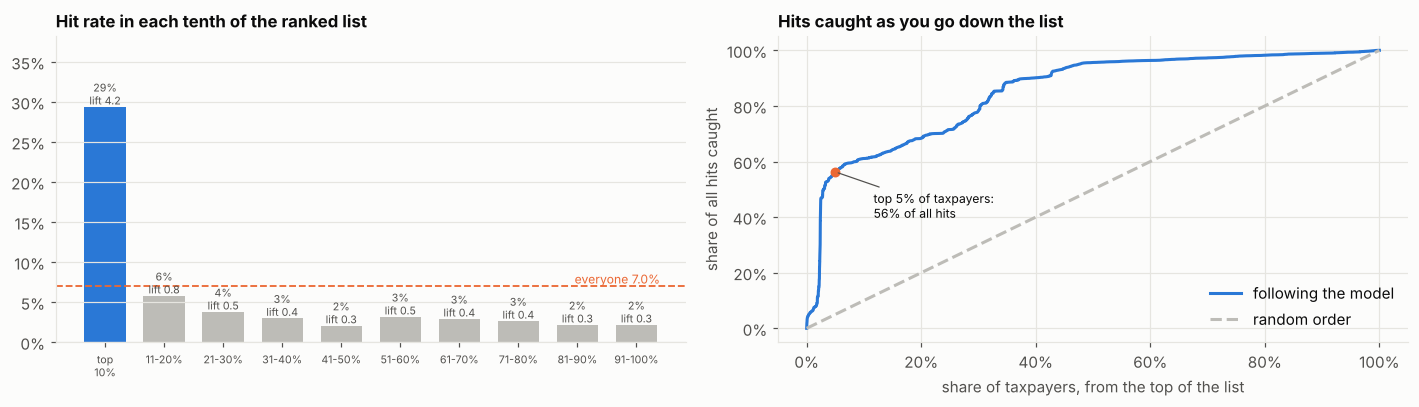

In [32]:
# What: hit rate in each tenth of the ranked list, and the share of all hits caught as you go down it.
# Why:  the picture behind "lift": a useful list is steep at the top and flat after.
m_ = sc.merge(ex[latest][['taxpayer_tin', 'out_checked', 'out_checked_hits']], on='taxpayer_tin').sort_values('rank')
base_ = hit_rate(m_)
m_['tenth'] = np.ceil(m_['rank'] / len(m_) * 10).astype(int)
g_ = m_.groupby('tenth').apply(hit_rate, include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
bars = ax.bar(g_.index, g_.values, color=[BLUE if i == 1 else MUTED for i in g_.index], width=0.7)
for b_, v in zip(bars, g_.values):
    ax.text(b_.get_x() + b_.get_width() / 2, v, f'{v:.0%}\nlift {v / base_:.1f}', ha='center', va='bottom', fontsize=7, color=INK2)
ax.axhline(base_, color=ORANGE, linestyle='--', linewidth=1.2)
ax.text(10.4, base_, f' everyone {base_:.1%}', color=ORANGE, fontsize=8, va='bottom', ha='right')
ax.set_xticks(range(1, 11), ['top\n10%'] + [f'{10 * i + 1}-{10 * (i + 1)}%' for i in range(1, 10)], fontsize=7)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, g_.max() * 1.3); ax.grid(axis='x', visible=False)
ax.set_title('Hit rate in each tenth of the ranked list', fontsize=11)
ax = axes[1]
share_list = np.arange(1, len(m_) + 1) / len(m_)
share_hits = m_['out_checked_hits'].cumsum().to_numpy() / m_['out_checked_hits'].sum()
ax.plot(share_list, share_hits, color=BLUE, label='following the model')
ax.plot([0, 1], [0, 1], color=MUTED, linestyle='--', label='random order')
k5 = int(round(0.05 * len(m_))) - 1
ax.scatter(share_list[k5], share_hits[k5], color=ORANGE, zorder=3, s=30)
ax.annotate(f'top 5% of taxpayers:\n{share_hits[k5]:.0%} of all hits', (share_list[k5], share_hits[k5]), xytext=(25, -30),
            textcoords='offset points', fontsize=8, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('share of taxpayers, from the top of the list'); ax.set_ylabel('share of all hits caught')
ax.set_title('Hits caught as you go down the list', fontsize=11); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

**Do the bands mean anything?** The hit rate in the 6 months after should climb band by band. If it does not,
the bands are labels without evidence.

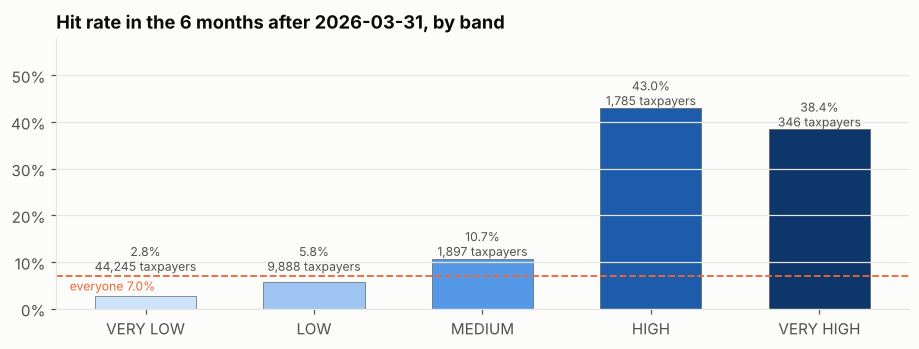

ranked_by,Model,Past top-ups only
top_share,,
top 1%,4.62,1.16
top 5%,5.38,1.39
top 10%,4.22,1.68


In [33]:
# What: later hit rate per band, and the model against the baseline.  Why: the evidence that bands rank risk.
lt, bb, base = M.backtest(res, ex[latest])
fig, ax = plt.subplots(figsize=(10, 3.2))
bars = ax.bar(bb['band'], bb['hit_rate'], color=RAMP, width=0.6, edgecolor=INK2, linewidth=0.4)
for b_, v, n_ in zip(bars, bb['hit_rate'], bb['taxpayers']):
    ax.text(b_.get_x() + b_.get_width() / 2, max(v, base['hit_rate'] * 1.08), f'{v:.1%}\n{int(n_):,} taxpayers', ha='center', va='bottom', fontsize=8, color=INK2)
ax.axhline(base['hit_rate'], color=ORANGE, linestyle='--', linewidth=1.2)
ax.text(-0.45, base['hit_rate'] * 0.93, f'everyone {base["hit_rate"]:.1%}', color=ORANGE, fontsize=8, va='top', ha='left')
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, bb['hit_rate'].max() * 1.35); ax.grid(axis='x', visible=False)
ax.set_title(f'Hit rate in the 6 months after {latest}, by band')
plt.show()
lt.pivot(index='top_share', columns='ranked_by', values='hit_lift').rename(index=lambda v: f'top {v:.0%}').style.format('{:.2f}')

**Finding for Stage 7.** The hit rate climbs from VERY LOW to HIGH, but in this snapshot VERY HIGH is hit
*less* often than HIGH (the same with or without pattern points). Section 7 shows this happens in the two most recent snapshots, not the four before.
The band cut-offs (and possibly the 100-point ceiling) are to be reviewed in Stage 7 with this in view.

In [34]:
# What: write the officers' workbook for this snapshot.  Why: the same file production will write.
RESULTS_DIR.mkdir(exist_ok=True)
out = R.write_workbook(res, RESULTS_DIR / f'CTRP_scores_{res.snapshot}.xlsx', source_file=f'data/bt_{latest}.csv')
print('written', out)

written /home/claude/ctrp_new/results/CTRP_scores_2026-03-31.xlsx


## 7. Back-test across all six snapshots

A model that works should beat the simple ranking (past top-ups alone) in every snapshot, not just on average.

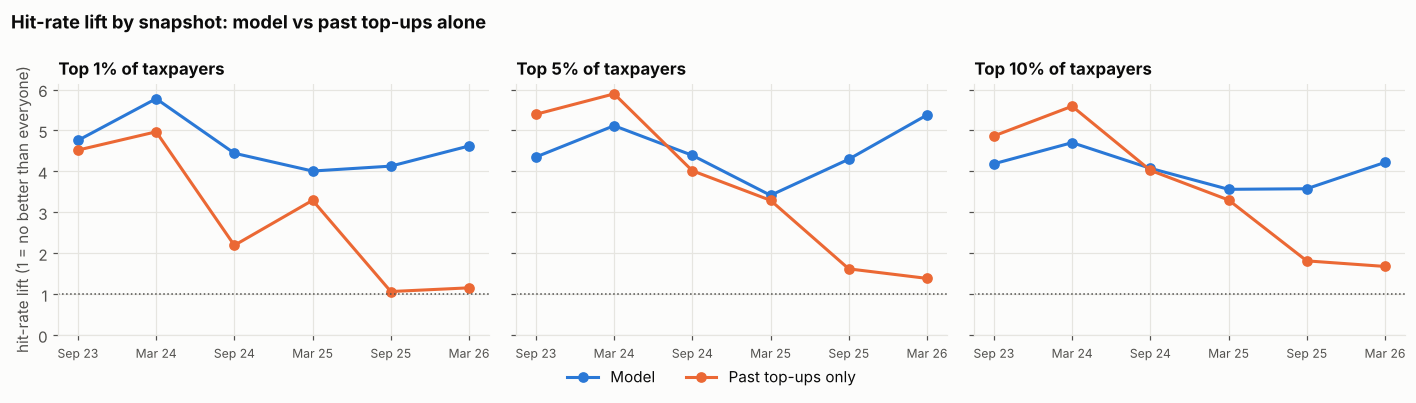

In [35]:
# What: lift of the model and the baseline in every snapshot.  Why: consistency over time, not one good year.
lifts, by_band = [], []
for snap, raw in ex.items():
    lt_, bb_, _ = M.backtest(M.score_snapshot(raw), raw)
    lifts.append(lt_); by_band.append(bb_)
lifts, by_band = pd.concat(lifts), pd.concat(by_band)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, share in zip(axes, [0.01, 0.05, 0.10]):
    for name, colr in [('Model', BLUE), ('Past top-ups only', ORANGE)]:
        s_ = lifts[(lifts['top_share'] == share) & (lifts['ranked_by'] == name)]
        ax.plot([snap_label(v) for v in s_['snapshot']], s_['hit_lift'], color=colr, marker='o', markersize=6, label=name)
    ax.axhline(1, color=INK2, linewidth=1, linestyle=':')
    ax.set_title(f'Top {share:.0%} of taxpayers', fontsize=11); ax.tick_params(axis='x', labelsize=8)
axes[0].set_ylabel('hit-rate lift (1 = no better than everyone)'); axes[0].set_ylim(bottom=0)
handles, labs = axes[0].get_legend_handles_labels()
fig.legend(handles, labs, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.06))
fig.suptitle('Hit-rate lift by snapshot: model vs past top-ups alone', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

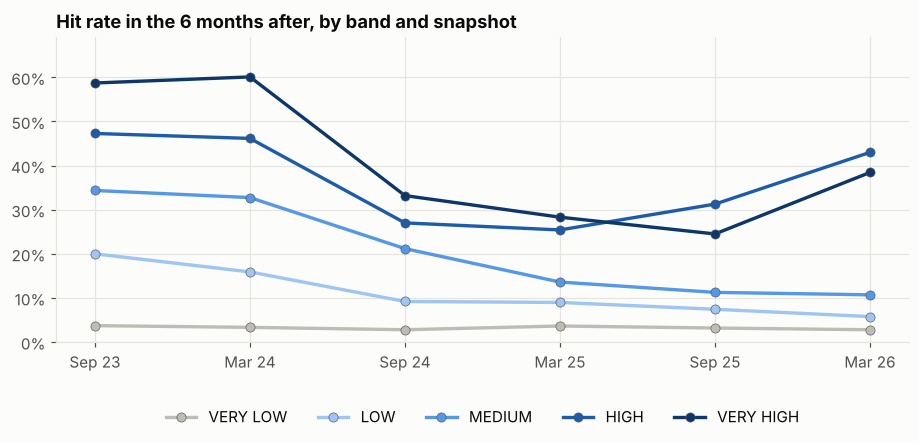

In [36]:
# What: later hit rate per band in every snapshot.  Why: bands must climb in order every time, not just once.
hb = by_band.pivot(index='snapshot', columns='band', values='hit_rate')[bands]
fig, ax = plt.subplots(figsize=(10, 3.6))
for b, colr in zip(bands, RAMP):
    ax.plot([snap_label(v) for v in hb.index], hb[b], color=colr if b != 'VERY LOW' else MUTED, marker='o',
            markersize=6, label=b, linewidth=2.2, markeredgecolor=INK2, markeredgewidth=0.4)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, hb.values.max() * 1.15)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.32), ncol=5)
ax.set_title('Hit rate in the 6 months after, by band and snapshot')
plt.show()

## 8. Live scores

Scores as at the live snapshot, written to the officers' workbook.

written /home/claude/ctrp_new/results/CTRP_scores_2026-09-30.xlsx


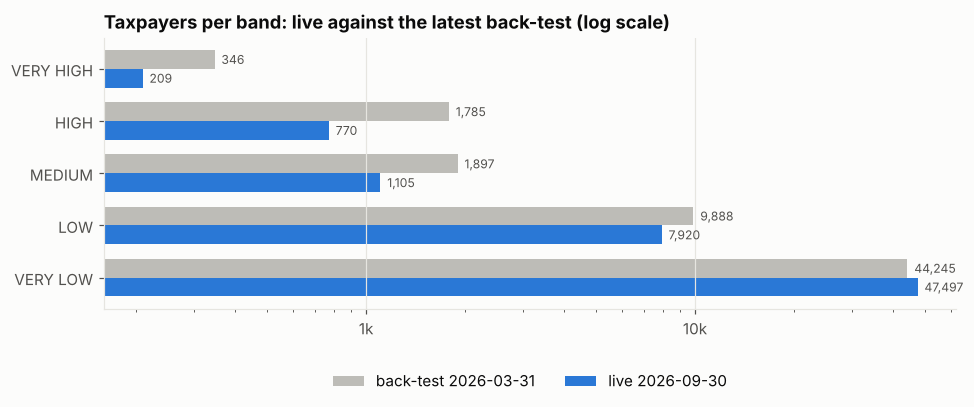

In [37]:
# What: score the live extract and write the workbook.  Why: this is the list the officers would receive.
if live_file.exists():
    live = M.score_snapshot(M.load_extract(live_file))
    out = R.write_workbook(live, RESULTS_DIR / f'CTRP_scores_{live.snapshot}.xlsx', source_file=str(live_file))
    print('written', out)
    comp = pd.DataFrame({f'back-test {latest}': sc['band'].value_counts(), f'live {live.snapshot}': live.scores['band'].value_counts()}).reindex(bands).fillna(0)
    fig, ax = plt.subplots(figsize=(10, 3.2))
    yy = np.arange(len(bands))
    for k, (col, colr) in enumerate(zip(comp.columns, [MUTED, BLUE])):
        bars = ax.barh(yy + (0.18 if k == 0 else -0.18), comp[col], height=0.36, color=colr, label=col)
        bar_labels(ax, bars)
    ax.set_yticks(yy, bands); ax.xaxis.set_major_formatter(big); ax.grid(axis='y', visible=False)
    ax.set_xscale('log'); ax.xaxis.set_major_formatter(big); ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.35), ncol=2)
    ax.set_title('Taxpayers per band: live against the latest back-test (log scale)')
    plt.show()
else:
    print('No live extract yet: run sql/live_2026-09-30.sql in Hue and save it to data/.')

## 9. Challenger models and ensembles, round 1

**Why compare at all?** A score can only be called good next to its alternatives. The question here: would
a different way of ranking the same taxpayers do better? Every challenger is built in `src/ctrp/models/challengers.py`
and judged exactly the same way.

**The fairness rules.**

1. Supervised models (the ones that learn from outcomes) train only on earlier snapshots whose 6-month outcome
   window had already closed. They never see the future they are tested on.
2. Tests run on the four latest snapshots (Sep 2024 to Mar 2026), so every supervised model has at least two
   snapshots to learn from.
3. Lift is never shown alone. Each model also shows **hits caught** and **revenue captured** in its top 5%, and
   the **share of small traders** there, because a model can raise its hit rate by filling the top with one-off
   importers while catching less.
4. "Better" or "worse" than the scorecard is only claimed when a 90% paired bootstrap interval of the top-5%
   lift difference excludes zero.

| Challenger | Idea | Learns from outcomes? |
|---|---|---|
| Baseline | rank on past top-up ratio | no |
| Learned weights | logistic regression on the same 8 scaled parameters | yes |
| Data-set shrinkage | the scorecard, with small-count rates shrunk by a strength estimated from the data | no |
| Monotone boosting | additive gradient boosting on the same 8 parameters, each forced to push risk up only | yes |
| Monotone boosting + size | the same, plus declarations and value (a warning case) | yes |
| Peer percentile | how much worse than the HS-section median, summed with expert weights | no |
| Ensemble, K-Means, Gaussian mixture | the Scope and Design candidates, given one-sided (worse-than-peer) features | no |
| Blends | each taxpayer gets the average of their rank positions in several models | no (members may) |
| Stacked blend | how much each member counts is learned from earlier snapshots | yes |

**Why blends?** Models that make different mistakes can cover for each other. The Scope and Design candidates
find big, high-volume traders; the scorecard finds frequent top-ups. A blend keeps a taxpayer at the top only if
several models agree.

In [38]:
# What: run every challenger and blend on every test snapshot (about ten minutes).
# Why:  the evidence for decisions 47 to 54.
table, detail, weights = CH.compare(ex)
with pd.ExcelWriter(RESULTS_DIR / 'CTRP_challengers.xlsx') as w_:
    table.to_excel(w_, sheet_name='Average of 4 tests'); detail.to_excel(w_, sheet_name='Per snapshot', index=False)
    weights.to_excel(w_, sheet_name='Weights')
    CH.compare.stack_weights.to_excel(w_, sheet_name='Stacked blend weights')
table.style.format({'lift_top1': '{:.2f}', 'lift_top5': '{:.2f}', 'lift_top10': '{:.2f}', 'hits_top5': '{:,.0f}',
                    'revenue_top5': '{:.0%}', 'small_share_top5': '{:.0%}', 'checked_in_top5': '{:.0%}',
                    'overlap_with_champion': '{:.0%}', 'rank_stability': '{:.2f}', 'corr_past_red_lane': '{:.2f}'})

,lift_top1,lift_top5,lift_top10,hits_top5,revenue_top5,small_share_top5,checked_in_top5,overlap_with_champion,rank_stability,corr_past_red_lane,vs_champion_top5 (of tests)
model,,,,,,,,,,,
Baseline (past top-up ratio),1.93,2.58,2.71,806,13%,94%,21%,22%,0.92,-0.25,0 better / 2 worse
Scorecard (champion),4.30,4.37,3.86,"5,522",45%,53%,49%,100%,0.92,-0.24,nan
Learned weights (logistic),4.11,5.00,4.49,"5,070",38%,59%,43%,82%,0.86,-0.19,3 better / 0 worse
Data-set shrinkage,4.87,3.97,3.50,"2,238",35%,78%,39%,56%,0.90,-0.06,0 better / 1 worse
Monotone boosting,5.71,4.75,4.13,"5,809",43%,53%,47%,84%,0.90,-0.22,3 better / 1 worse
Monotone boosting + size (warning case),7.33,6.30,5.85,"3,508",19%,83%,34%,53%,0.87,-0.08,4 better / 0 worse
Peer percentile (one-sided),3.65,3.48,2.62,"4,228",45%,53%,50%,72%,0.91,-0.24,0 better / 4 worse
Ensemble IF + PCA (one-sided),3.49,2.13,1.26,"6,678",50%,42%,56%,43%,0.88,-0.21,0 better / 4 worse
K-Means distance (one-sided),3.41,2.49,1.46,"6,424",45%,37%,59%,44%,0.86,-0.22,0 better / 4 worse


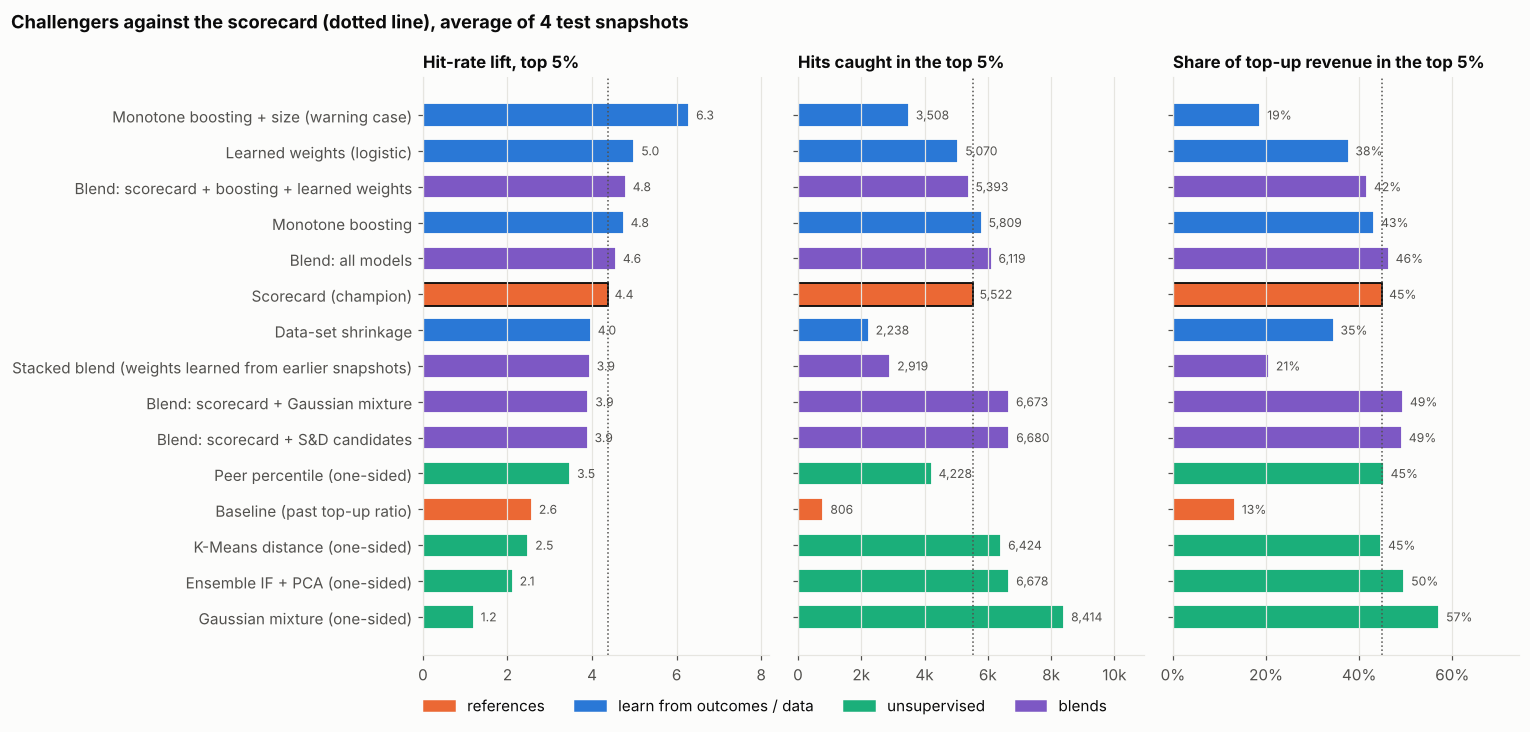

In [39]:
# What: lift, hits caught and revenue captured in the top 5%, side by side.
# Why:  the three can disagree; reading only one of them misleads.
order_ = table['lift_top5'].sort_values().index
PURPLE = '#7d58c4'
kind = {n: (ORANGE if n.startswith(('Baseline', 'Scorecard')) else PURPLE if n.startswith(('Blend', 'Stacked'))
            else BLUE if n in CH.SUPERVISED or n == 'Data-set shrinkage' else AQUA) for n in order_}
fig, axes = plt.subplots(1, 3, figsize=(14, 6.4), sharey=True)
for ax, col, title, fmt in [(axes[0], 'lift_top5', 'Hit-rate lift, top 5%', '{:.1f}'),
                            (axes[1], 'hits_top5', 'Hits caught in the top 5%', '{:,.0f}'),
                            (axes[2], 'revenue_top5', 'Share of top-up revenue in the top 5%', '{:.0%}')]:
    v = table.loc[order_, col]
    bars = ax.barh(order_, v, color=[kind[n] for n in order_], height=0.65,
                   edgecolor=[INK if n.startswith('Scorecard') else SURFACE for n in order_], linewidth=1.2)
    for b_, x_ in zip(bars, v):
        ax.text(x_, b_.get_y() + b_.get_height() / 2, '  ' + fmt.format(x_), va='center', fontsize=8, color=INK2)
    champ = table.loc['Scorecard (champion)', col]
    ax.axvline(champ, color=INK2, linestyle=':', linewidth=1)
    ax.set_title(title, fontsize=11); ax.grid(axis='y', visible=False); ax.set_xlim(0, v.max() * 1.3)
    if col == 'revenue_top5':
        ax.xaxis.set_major_formatter(pct)
    elif col == 'hits_top5':
        ax.xaxis.set_major_formatter(big)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=ORANGE, label='references'), Patch(color=BLUE, label='learn from outcomes / data'),
                    Patch(color=AQUA, label='unsupervised'), Patch(color=PURPLE, label='blends')],
           loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('Challengers against the scorecard (dotted line), average of 4 test snapshots', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

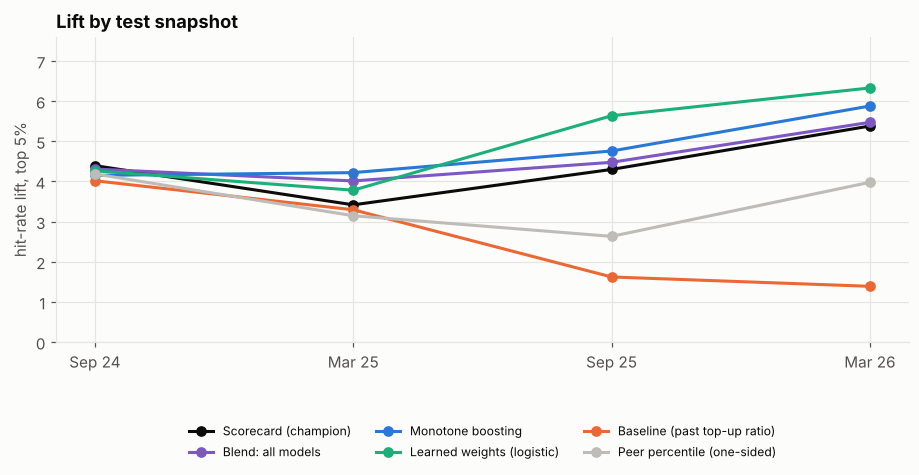

In [40]:
# What: lift at the top 5% in each test snapshot for the leading models.
# Why:  a challenger should win consistently, not on average thanks to one good snapshot.
lead = ['Scorecard (champion)', 'Blend: all models', 'Monotone boosting', 'Learned weights (logistic)',
        'Baseline (past top-up ratio)', 'Peer percentile (one-sided)']
fig, ax = plt.subplots(figsize=(10, 3.6))
for n, colr in zip(lead, [INK, '#7d58c4', BLUE, AQUA, ORANGE, MUTED]):
    s_ = detail[detail['model'] == n]
    ax.plot([snap_label(v) for v in s_['snapshot']], s_['lift_top5'], color=colr, marker='o', markersize=6, label=n)
ax.set_ylim(0, detail[detail['model'].isin(lead)]['lift_top5'].max() * 1.2)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.42), ncol=3, fontsize=8)
ax.set_ylabel('hit-rate lift, top 5%'); ax.set_title('Lift by test snapshot')
plt.show()

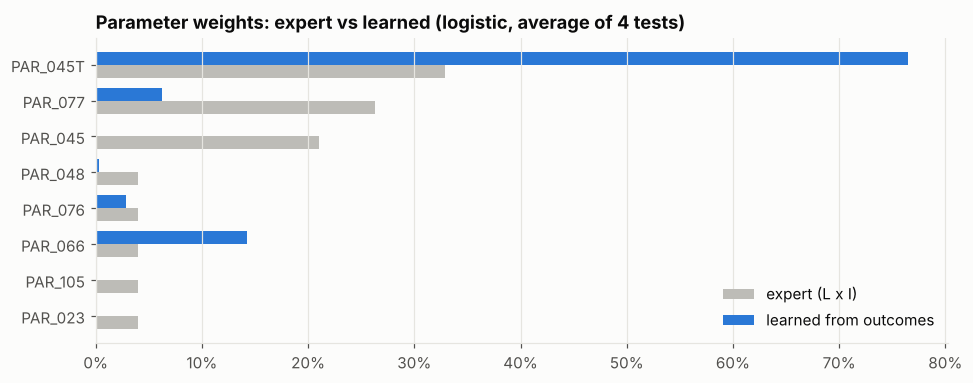

Shrinkage strength K estimated from the data (current fixed value is 10): {'top_up_entry_rate': 3.3, 'par077_severe_top_up_rate': 3.8, 'par045_amended_entry_rate': 3.1, 'par066_negative_top_up_rate': 65.5, 'par076_shortfall_share': 0.7}


In [41]:
# What: the weights the outcomes "would choose" next to the expert weights.
# Why:  evidence for the ratings session; learned weights carry selectivity bias, so they inform, not replace.
wt = weights.copy()
fig, ax = plt.subplots(figsize=(10, 3.6))
yy = np.arange(len(wt))
ax.barh(yy + 0.18, wt['expert weight'], height=0.36, color=MUTED, label='expert (L x I)')
ax.barh(yy - 0.18, wt['learned weight (average)'], height=0.36, color=BLUE, label='learned from outcomes')
ax.set_yticks(yy, wt.index); ax.invert_yaxis(); ax.xaxis.set_major_formatter(pct); ax.grid(axis='y', visible=False)
ax.legend(loc='lower right'); ax.set_title('Parameter weights: expert vs learned (logistic, average of 4 tests)')
plt.show()
print('Shrinkage strength K estimated from the data (current fixed value is 10):',
      {k: round(float(v), 1) for k, v in CH.score_eb.last_k.items()})

### 9.1 What the comparison says

* **The scorecard holds up.** Only two challengers beat it on lift: monotone boosting on the same eight inputs
  (better in 3 of 4 tests, worse in 1, about 5% more hits, same revenue and trader mix) and learned weights
  (better in 3 of 4 on lift, but fewer hits and less revenue). Neither gain is large or clean enough to replace
  a model officers can read in their own thresholds. **Decision 47:** the scorecard stays for release 1; both go
  to round 2.
* **The warning case.** Adding size to boosting gives the highest lift of all (6.3) by filling the top 5% with
  one-off importers: 83% small traders, fewer hits and only 19% of revenue. Hence **decision 48**: lift is
  never reported alone.
* **Data-set shrinkage loses.** The data put the shrinkage strength K near 3, not 10, and two-way shrinkage
  pushed small traders to the top. One-way K = 10 stays (**decision 49**).
* **The Scope and Design candidates lose on lift in every test**, even with one-sided features (**decision 50**).
  They catch more revenue because they pick large, high-volume traders. That is a different goal, and the
  question for the Risk Officers is which goal the list should serve.
* **Weights.** Once the share topped up is known, the outcomes give amendments (PAR_045) no extra weight and
  PAR_066 more than the experts did (**decision 51**). This is for the ratings session, not an automatic change.
* **Ensembles.** The blend of all models is the only model that improves lift, hits caught and revenue caught
  together (better in 2 of 4 tests, worse in none). Everyone in its top 5% also has 15 or more scorecard points,
  so the scorecard's reasons still explain it. It is the leading round 2 challenger (**decision 52**). The learned
  (stacked) blend is unstable with so few snapshots (**decision 53**), and blends with the Scope and Design
  candidates trade efficiency for volume (**decision 54**).